# UTS Visi Komputer — Deteksi Garis Marka Lajur pada Video

## Bagian 1. Identitas Kelompok
- **Nomor Kelompok:** 6
- **Tema Tugas:** Deteksi garis marka lajur (kiri & kanan) pada video jalan yang direkam dari kendaraan
- **Anggota Kelompok:**
  1. Riyan Hadi Samudra — 2308107010068
  2. Muhammad Fanzal Rivaldi — 2308107010077
  3. Farhan Mujiburrahman — 2308107010078
  4. Razian Sabri — 2308107010050

**Ringkasan pendekatan.** Pipeline dibuat **universal**: video apa pun cukup dimasukkan tanpa mengatur angka.
1. **Kalibrasi otomatis (sekali per video).** Dari 30 frame yang tersebar di video, dicari **titik hilang** (tempat garis-garis marka bertemu) dengan voting segmen `HoughLinesP`, lalu dicari **batas bawah jalan** (tempat kap mobil/dasbor motor mulai) dari warna aspal pada HSV. Keduanya membentuk **mask ROI trapesium** dan baris acuan.
2. **Per frame.** `VideoCapture` → `resize` → *grayscale* → *Gaussian blur* → `Canny` (ambang dihitung otomatis dari gradien) ∩ mask ROI ∩ masker marka terang (`adaptiveThreshold`) → `HoughLinesP` → pemilihan garis kiri/kanan → hasil digambar dan ditulis dengan `VideoWriter` ke `.mp4`.

**Definisi garis kiri dan kanan.** Garis **kiri** adalah garis tepi jalan di sisi kiri lajur kendaraan. Garis **kanan** adalah marka tengah (putus-putus atau menerus) di sisi kanan lajur kendaraan.

**Aturan evaluasi.** Hanya ada **satu set parameter untuk semua klip, dan tidak ada nilai yang disetel per klip** (termasuk ROI). Ground truth berisi anotasi manual posisi garis (lihat Bagian 3), bukan keluaran program.

---
## Bagian 2. Import dan Fungsi Bantu
Setiap tahap pipeline ditulis sebagai fungsi: `praproses()`, `segmentasi()`, `deteksi()`, `kalibrasi_video()`, lalu `gambar_hasil()` untuk visualisasi dan `evaluasi_gt()` untuk perbandingan dengan ground truth. Hanya memakai `opencv-python`, `numpy`, dan `matplotlib` (ditambah modul bawaan Python `os`, `csv`, `json`, `time`).

Fungsi-fungsi pipeline yang sama juga disimpan di `lane_pipeline.py` agar bisa dipakai di luar notebook: `python deteksi.py video.mp4`.

In [1]:
import os, csv, json, time
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Pastikan path folder dataset dan output terdeteksi secara fleksibel
for candidate in ["dataset", "UTS_VisKom_Kelompok06/dataset", "../dataset"]:
    if os.path.exists(candidate) and os.path.isdir(candidate):
        DATASET_DIR = candidate
        break
else:
    DATASET_DIR = "dataset"

OUTPUT_DIR = os.path.join(os.path.dirname(DATASET_DIR), "output") if os.path.basename(DATASET_DIR) != "dataset" else "output"
GT_CSV = os.path.join(DATASET_DIR, "ground_truth.csv")
for sub in ["videos", "pipeline_steps", "ground_truth", "experiments"]:
    os.makedirs(os.path.join(OUTPUT_DIR, sub), exist_ok=True)

# Daftar klip: HANYA nama berkas video. Tidak ada ROI, ambang, atau baris acuan per klip;
# semuanya dihitung otomatis dari isi video oleh kalibrasi_video() di Bagian 2.4.
KLIP = {
    "klip1_ideal1":      "ideal/20261024_075053.mp4",
    "klip2_ideal2":      "ideal/WhatsApp Video 2026-10-24 at 09.30.44.mp4",
    "klip3_menikung":    "jalan menikung/WhatsApp Video 2026-10-24 at 09.30.37.mp4",
    "klip4_sulit_glare": "sulit/20261024_074800.mp4",
    "klip5_sulit_malam": "sulit/malam.mp4",
}


def cari_path_video(rel_path):
    """Mencari lokasi berkas video di dalam folder dataset/ (baik dalam subfolder maupun langsung)."""
    p = os.path.join(DATASET_DIR, rel_path)
    if os.path.exists(p):
        return p
    nama = os.path.basename(rel_path)
    for root, _, files in os.walk(DATASET_DIR):
        if nama in files:
            return os.path.join(root, nama)
    return p


def cetak_tabel(baris, kolom=None, judul=None):
    """Cetak list of dict sebagai tabel teks rata kiri."""
    if judul:
        print(judul)
    kolom = kolom or list(baris[0].keys())
    fmt = lambda v: "" if v is None else ((f"{v:.2f}" if abs(v) < 1 else f"{v:.1f}") if isinstance(v, float) else str(v))
    teks = [[fmt(b.get(k)) for k in kolom] for b in baris]
    lebar = [max(len(k), *(len(t[i]) for t in teks)) for i, k in enumerate(kolom)]
    print("  ".join(k.ljust(l) for k, l in zip(kolom, lebar)))
    print("  ".join("-" * l for l in lebar))
    for t in teks:
        print("  ".join(s.ljust(l) for s, l in zip(t, lebar)))


def simpan_csv(path, baris, kolom=None):
    kolom = kolom or list(baris[0].keys())
    with open(path, "w", newline="", encoding="utf-8") as f:
        wr = csv.DictWriter(f, fieldnames=kolom, extrasaction="ignore")
        wr.writeheader()
        wr.writerows(baris)


print("OpenCV", cv2.__version__, "| NumPy", np.__version__)
print(f"DATASET_DIR: {DATASET_DIR} | OUTPUT_DIR: {OUTPUT_DIR}")

OpenCV 5.0.0 | NumPy 2.5.4
DATASET_DIR: dataset | OUTPUT_DIR: output


In [2]:
TARGET_MAX_SIDE = 1000          # sisi terpanjang setelah resize (aturan: 800-1200 px)

# SATU set parameter untuk SEMUA video. Tidak ada nilai yang disetel per klip:
# ROI, baris acuan, dan ambang Canny dihitung otomatis dari isi videonya sendiri.
PARAM = dict(
    blur_ksize=5,
    # Canny adaptif: ambang atas = persentil ke-97 besar gradien di dalam ROI, ambang bawah = 0.4 x ambang atas
    canny_persentil=97, canny_rasio_bawah=0.4, canny_min=15,
    # Masker "lebih terang dari sekitarnya" (adaptiveThreshold) untuk membuang tepi tekstur aspal
    terang_blok=31, terang_C=10, terang_lebar=7,
    # HoughLinesP untuk deteksi per frame
    hough_rho=1, hough_theta=np.pi / 180, hough_thr=25, hough_min_len=25, hough_max_gap=60,
    # Kalibrasi titik hilang (sekali per video)
    kal_n_frame=30, kal_y_atas=0.05, kal_hough=(30, 40, 20), kal_tol_px=12,
    vp_y_rentang=(0.0, 0.65),    # titik hilang dicari pada 0-65% tinggi frame (kamera boleh menunduk)
    # ROI trapesium yang dibentuk dari titik hilang (semua dalam proporsi tinggi/lebar frame)
    roi_bawah=0.93, roi_turun=0.05, roi_lebar_atas=0.25, pos_ref=0.60,
    aspal_min=0.35,              # baris dianggap bukan jalan lagi bila < 35% piksel tengahnya mirip aspal
    # Pemilihan garis kiri/kanan
    vp_tol=0.15,                 # segmen harus mengarah ke titik hilang (toleransi, proporsi lebar)
    inv_tegak=0.15,              # |dx/dy| < 0.15 dianggap hampir tegak -> marka tengah (sisi kanan)
    kontras_min=20,              # marka harus lebih terang dari aspal di sekitarnya
    gap_klaster=25, bobot_min=40,
    lebar_lajur_min=120,         # lebar lajur minimal (px) pada baris acuan
    alpha=0.4, hold=6,           # smoothing antar-frame (hanya untuk video)
    toleransi_px=50, margin_px=20,   # kriteria evaluasi
)

### 2.1 Fungsi `praproses()` — resize, grayscale, Gaussian blur

In [3]:
def resize_frame(frame, target=TARGET_MAX_SIDE):
    h, w = frame.shape[:2]
    s = target / float(max(h, w))
    interp = cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR
    return cv2.resize(frame, (int(round(w * s)), int(round(h * s))), interpolation=interp)


def praproses(raw, P=PARAM):
    # BGR -> resize -> grayscale -> Gaussian blur. Mengembalikan (frame, gray, blur).
    frame = resize_frame(raw)
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (P["blur_ksize"], P["blur_ksize"]), 0)
    return frame, gray, blur

### 2.2 Fungsi `segmentasi()` — Canny (ambang otomatis), mask ROI trapesium, masker marka terang
- **Ambang Canny otomatis.** Ambang atas = persentil ke-97 besar gradien di dalam ROI, ambang bawah = 0,4 × ambang atas. Karena dihitung dari gradien (bukan angka tetap), ambang ikut turun pada video gelap atau buram dan naik pada video tajam.
- **Masker marka terang** (`cv2.adaptiveThreshold` dengan C negatif). Piksel dianggap marka bila lebih terang 10 tingkat daripada rata-rata 31×31 di sekitarnya. Retakan, bekas ban, dan bayangan lebih gelap daripada sekitarnya, sehingga tepinya dibuang. Masker diperlebar dengan *average blur* 7×7 + threshold > 0 agar tepi di kedua sisi marka tetap masuk.

In [4]:
def buat_mask_roi(shape, roi):
    h, w = shape[:2]
    pts = np.array([[int(round(x * w)), int(round(y * h))] for x, y in roi], np.int32)
    mask = np.zeros((h, w), np.uint8)
    cv2.fillPoly(mask, [pts], 255)
    return mask, pts


def ambang_canny_otomatis(blur, mask, P=PARAM):
    # Ambang Canny dari sebaran BESAR GRADIEN di dalam ROI (bukan dari kecerahan), sehingga ikut menyesuaikan
    # bila video tajam/buram, terang/gelap, atau resolusinya rendah. Sebagian besar ROI adalah aspal tanpa tepi,
    # jadi hanya ~3% piksel dengan gradien terbesar (persentil 97) yang dianggap tepi kuat.
    # Gradien dihitung dengan beda pusat np.gradient lalu dikali 8 agar skalanya setara Sobel 3x3 yang dipakai Canny.
    gy, gx = np.gradient(blur.astype(np.float32))
    besar = 8 * (np.abs(gx) + np.abs(gy))
    high = max(2 * P["canny_min"], float(np.percentile(besar[mask > 0], P["canny_persentil"])))
    low = max(P["canny_min"], P["canny_rasio_bawah"] * high)
    return int(low), int(high)


def mask_marka_terang(blur, P=PARAM):
    # Piksel yang lebih terang daripada rata-rata lingkungannya sebesar C (adaptive threshold dengan C negatif).
    # Marka putih/kuning lolos; retakan, bekas ban, dan bayangan (lebih gelap) tidak lolos.
    # Lalu diperlebar dengan average blur + threshold > 0 agar tepi di kedua sisi marka ikut masuk.
    m = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, P["terang_blok"], -P["terang_C"])
    k = P["terang_lebar"]
    return cv2.threshold(cv2.blur(m, (k, k)), 0, 255, cv2.THRESH_BINARY)[1]


def segmentasi(blur, kal, canny=None, P=PARAM):
    # Canny (ambang otomatis, atau pasangan tetap `canny` untuk eksperimen) AND mask ROI AND masker terang.
    mask, pts = buat_mask_roi(blur.shape, kal["roi"])
    low, high = ambang_canny_otomatis(blur, mask, P) if canny is None else canny
    edges = cv2.Canny(blur, low, high)
    terang = mask_marka_terang(blur, P)
    roi_edges = cv2.bitwise_and(cv2.bitwise_and(edges, mask), terang)
    return dict(edges=edges, mask=mask, pts=pts, terang=terang, roi_edges=roi_edges, canny=(low, high))

### 2.3 Fungsi `deteksi()` — HoughLinesP, pemilihan garis kiri/kanan, fitting

In [5]:
def kontras_marka(gray, x1, y1, x2, y2, dalam=8, jauh=(16, 30)):
    # Seberapa terang punggung marka dibanding aspal di kedua sisinya (rata-rata sepanjang segmen).
    h, w = gray.shape
    nilai = []
    for t in np.linspace(0.1, 0.9, 7):
        y = int(np.clip(y1 + t * (y2 - y1), 1, h - 2))
        x = int(round(x1 + t * (x2 - x1)))
        baris = gray[y].astype(np.float32)
        def potong(a, b):
            a = int(np.clip(x + a, 0, w - 1)); b = int(np.clip(x + b, 0, w))
            return baris[a:b] if b > a else baris[a:a + 1]
        puncak = potong(-dalam, dalam + 1).max()
        kiri, kanan = np.median(potong(-jauh[1], -jauh[0])), np.median(potong(jauh[0], jauh[1]))
        nilai.append(puncak - min(kiri, kanan))
    return float(np.mean(nilai))


def klaster_x(segmen, gap):
    # Kelompokkan segmen yang x-nya pada baris acuan berdekatan (satu kelompok = satu garis fisik).
    segmen = sorted(segmen, key=lambda s: s[0])
    kelompok = []
    for s in segmen:
        if kelompok and s[0] - kelompok[-1][-1][0] < gap:
            kelompok[-1].append(s)
        else:
            kelompok.append([s])
    return kelompok


def pilih_garis(garis, gray, y_ref, vp, P=PARAM):
    # Saring segmen yang mengarah ke titik hilang, pisahkan kiri/kanan, lalu ambil garis TERDEKAT ke kendaraan.
    h, w = gray.shape
    vx, vy = vp
    kiri, kanan = [], []
    if garis is None:
        return [], []
    for x1, y1, x2, y2 in np.reshape(garis, (-1, 4)):
        dy, dx = float(y2 - y1), float(x2 - x1)
        if abs(dy) < 10:                       # buang garis (hampir) horizontal: garis kejut, zebra cross
            continue
        inv = dx / dy
        if abs(x1 + inv * (vy - y1) - vx) > P["vp_tol"] * w:   # perpanjangan segmen harus lewat dekat titik hilang
            continue
        if kontras_marka(gray, x1, y1, x2, y2) < P["kontras_min"]:
            continue
        x_ref = x1 + inv * (y_ref - y1)
        s = (x_ref, x1, y1, x2, y2, float(np.hypot(dx, dy)))
        if inv < -P["inv_tegak"] and x_ref < vx:                                  # miring ke kanan-atas
            kiri.append(s)
        elif inv >= -P["inv_tegak"] and x_ref >= vx - P["inv_tegak"] * (y_ref - vy):  # miring ke kiri-atas / tegak
            kanan.append(s)

    def terbaik(kandidat, sisi):
        kel = [k for k in klaster_x(kandidat, P["gap_klaster"]) if sum(s[5] for s in k) >= P["bobot_min"]]
        if not kel:
            return []
        kel.sort(key=lambda k: np.average([s[0] for s in k], weights=[s[5] for s in k]))
        k = kel[-1] if sisi == "kiri" else kel[0]     # kiri: paling kanan; kanan: paling kiri
        return [s[1:] for s in k]
    return terbaik(kiri, "kiri"), terbaik(kanan, "kanan")


def fit_garis(segmen):
    # Regresi x = a*y + b berbobot panjang segmen. Mengembalikan (a, b) atau None.
    if not segmen:
        return None
    ys, xs, ws = [], [], []
    for x1, y1, x2, y2, pj in segmen:
        ys += [y1, y2]; xs += [x1, x2]; ws += [pj, pj]
    ys, xs = np.array(ys, float), np.array(xs, float)
    if np.ptp(ys) < 8:
        return None
    a, b = np.polyfit(ys, xs, 1, w=np.array(ws))
    return float(a), float(b)


def x_pada_baris(model, y):
    return None if model is None else model[0] * y + model[1]


def konsistensi(model_kiri, model_kanan, seg_kiri, seg_kanan, y_ref, y_atas, y_bawah, P=PARAM):
    # Garis kiri harus berada di kiri garis kanan di seluruh tinggi ROI dan lajur tidak boleh terlalu sempit.
    # Bila dilanggar, sisi dengan bukti (total panjang segmen) lebih kecil dibuang. Mengembalikan (kiri, kanan, menyilang).
    if model_kiri is None or model_kanan is None:
        return model_kiri, model_kanan, False
    lebar = lambda y: x_pada_baris(model_kanan, y) - x_pada_baris(model_kiri, y)
    if min(lebar(y_atas), lebar(y_bawah)) > 0 and lebar(y_ref) >= P["lebar_lajur_min"]:
        return model_kiri, model_kanan, False
    bukti_k, bukti_r = sum(s[4] for s in seg_kiri), sum(s[4] for s in seg_kanan)
    return (model_kiri, None, True) if bukti_k >= bukti_r else (None, model_kanan, True)


def deteksi(roi_edges, gray, kal, P=PARAM):
    # HoughLinesP -> pilih segmen kiri/kanan -> fitting garis -> cek konsistensi geometri.
    h = gray.shape[0]
    y_ref, roi = kal["y_ref"] * h, kal["roi"]
    t0 = time.perf_counter()
    garis = cv2.HoughLinesP(roi_edges, P["hough_rho"], P["hough_theta"], P["hough_thr"],
                            minLineLength=P["hough_min_len"], maxLineGap=P["hough_max_gap"])
    waktu_ms = (time.perf_counter() - t0) * 1000
    kiri, kanan = pilih_garis(garis, gray, y_ref, kal["vp"], P)
    mk, mr = fit_garis(kiri), fit_garis(kanan)
    mk, mr, menyilang = konsistensi(mk, mr, kiri, kanan, y_ref, roi[1][1] * h, roi[0][1] * h, P)
    return dict(garis=garis, seg_kiri=kiri, seg_kanan=kanan, model_kiri=mk, model_kanan=mr, menyilang=menyilang,
                waktu_ms=waktu_ms, n_garis=0 if garis is None else len(garis))

### 2.4 Kalibrasi otomatis `kalibrasi_video()` — titik hilang dan batas bawah jalan
Dilakukan **sekali per video** dari 30 frame yang tersebar merata, menggantikan ROI yang dulu diatur manual per klip.
1. **Titik hilang.** Pada tiap frame sampel dicari segmen `HoughLinesP` yang kemiringannya wajar untuk marka (|dx/dy| 0,25–3) dan lebih terang daripada aspal di sekitarnya. Setiap titik kandidat pada grid 8 px diberi skor = total panjang segmen **kiri** yang perpanjangannya lewat dekat titik itu × total panjang segmen **kanan** yang lewat dekat titik itu (diakarkan). Segmen hanya boleh mendukung titik yang berada **di atasnya**, karena marka jalan selalu berada di bawah horizon. Titik dengan skor tertinggi menjadi titik hilang.
2. **Batas bawah jalan.** Contoh warna aspal diambil tepat di bawah titik hilang (HSV). Dari titik hilang ke bawah dicari baris pertama yang piksel tengahnya kurang dari 35% mirip aspal. Di situlah kap mobil, dasbor, atau bodi motor mulai. Bila jalan terlihat sampai bawah, dipakai batas 0,93 (di atas spion/kap).
3. **ROI trapesium.** Sisi atas = 5% tinggi frame di bawah titik hilang, selebar ±25% lebar frame dari titik hilang. Sisi bawah = batas bawah jalan, selebar frame. Baris acuan pemilihan garis = 60% dari atas ke bawah ROI.

In [6]:
def segmen_kalibrasi(gray, blur, P=PARAM):
    # Segmen HoughLinesP pada pita bawah frame yang kemiringannya wajar untuk marka dan lebih terang dari aspal.
    # Mengembalikan daftar (a, b, panjang, y_teratas) dengan persamaan garis x = a*y + b.
    h, w = gray.shape
    pita = np.zeros_like(gray)
    pita[int(P["kal_y_atas"] * h):int(P["roi_bawah"] * h), :] = 255
    low, high = ambang_canny_otomatis(blur, pita, P)
    edges = cv2.bitwise_and(cv2.Canny(blur, low, high), pita)
    thr, min_len, gap = P["kal_hough"]
    garis = cv2.HoughLinesP(edges, 1, np.pi / 180, thr, minLineLength=min_len, maxLineGap=gap)
    hasil = []
    if garis is None:
        return hasil
    for x1, y1, x2, y2 in garis.reshape(-1, 4):
        dy, dx = float(y2 - y1), float(x2 - x1)
        if abs(dy) < 10:
            continue
        a = dx / dy
        if not (0.25 <= abs(a) <= 3.0):
            continue
        if kontras_marka(gray, x1, y1, x2, y2) < P["kontras_min"]:
            continue
        hasil.append((a, x1 - a * y1, float(np.hypot(dx, dy)), float(min(y1, y2))))
    return hasil


def titik_hilang(garis, h, w, P=PARAM):
    # Voting: setiap titik kandidat (grid 8 px) diberi skor = total panjang segmen kiri yang perpanjangannya
    # lewat dalam kal_tol_px dari titik itu, begitu juga untuk segmen kanan. Skor akhir = sqrt(kiri * kanan),
    # sehingga titik hilang harus didukung OLEH KEDUA SISI jalan sekaligus.
    if not garis:
        return None
    xs = np.arange(0.2 * w, 0.8 * w, 8)
    ys = np.arange(P["vp_y_rentang"][0] * h, P["vp_y_rentang"][1] * h, 8)
    X, Y = np.meshgrid(xs, ys)
    skor_kiri, skor_kanan = np.zeros_like(X), np.zeros_like(X)
    for a, b, panjang, y_teratas in garis:
        # segmen harus mengarah ke titik itu DAN seluruhnya berada di bawahnya (marka jalan ada di bawah horizon)
        kena = (np.abs(a * Y + b - X) < P["kal_tol_px"]) & (Y < y_teratas)
        if a < 0:
            skor_kiri += kena * panjang
        else:
            skor_kanan += kena * panjang
    skor = cv2.GaussianBlur(np.sqrt(skor_kiri * skor_kanan).astype(np.float32), (5, 5), 0)
    if skor.max() <= 0:
        return None
    i, j = np.unravel_index(np.argmax(skor), skor.shape)
    return float(X[i, j]), float(Y[i, j])


def profil_aspal(frame, vp, P=PARAM):
    # Untuk tiap baris: proporsi piksel di tengah frame yang warnanya mirip aspal.
    # Contoh aspal diambil tepat di bawah titik hilang (hampir selalu jalan di depan kendaraan).
    # "Mirip aspal" = kecerahan (V pada HSV) dekat dengan contoh DAN saturasi (S) rendah.
    h, w = frame.shape[:2]
    vx, vy = vp
    hsv = cv2.cvtColor(cv2.GaussianBlur(frame, (9, 9), 0), cv2.COLOR_BGR2HSV)
    V, S = hsv[..., 2].astype(np.float32), hsv[..., 1].astype(np.float32)
    y0, y1 = int(vy + 0.05 * h), int(vy + 0.12 * h)
    x0, x1 = int(max(0, vx - 0.08 * w)), int(min(w, vx + 0.08 * w))
    contoh_v, contoh_s = V[y0:y1, x0:x1], S[y0:y1, x0:x1]
    m = float(np.median(contoh_v))
    sebaran = max(12.0, 1.5 * float(np.percentile(np.abs(contoh_v - m), 75)))
    aspal = (np.abs(V - m) < 2.5 * sebaran) & (S < float(np.median(contoh_s)) + 40)
    xa, xb = int(max(0, vx - 0.2 * w)), int(min(w, vx + 0.2 * w))
    return aspal[:, xa:xb].mean(axis=1)


def batas_bawah_jalan(profil, vy, h, P=PARAM):
    # Baris pertama di bawah titik hilang yang sudah TIDAK mirip aspal lagi (kap mobil, dasbor/bodi motor).
    # Bila jalan terlihat sampai bawah, dipakai batas bawaan roi_bawah.
    prof = np.convolve(np.median(np.array(profil), axis=0), np.ones(9) / 9, mode="same")
    batas = P["roi_bawah"] * h
    for y in range(int(vy + 0.10 * h), int(P["roi_bawah"] * h)):
        if prof[y] < P["aspal_min"]:
            batas = y - 0.02 * h
            break
    return max(batas, vy + 0.20 * h) / h


def roi_dari_titik_hilang(vp, w, h, P=PARAM, y_bawah=None):
    # Trapesium: sisi atas sedikit di bawah titik hilang, sisi bawah selebar frame di atas kap/bodi kendaraan.
    vx, vy = vp
    y_atas = vy / h + P["roi_turun"]
    y_bawah = P["roi_bawah"] if y_bawah is None else y_bawah
    xa_kiri = max(0.0, vx / w - P["roi_lebar_atas"])
    xa_kanan = min(1.0, vx / w + P["roi_lebar_atas"])
    roi = [(0.0, y_bawah), (xa_kiri, y_atas), (xa_kanan, y_atas), (1.0, y_bawah)]
    y_ref = y_atas + P["pos_ref"] * (y_bawah - y_atas)
    return dict(vp=(vx, vy), roi=roi, y_ref=y_ref)


def kalibrasi_video(path, P=PARAM):
    # Sekali per video: ambil kal_n_frame frame yang tersebar merata, cari titik hilang dari segmen marka,
    # lalu cari batas bawah jalan dari warna aspal. Hasilnya ROI trapesium + baris acuan untuk SEMUA frame.
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise ValueError(f"Video tidak bisa dibuka: {path}")
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    garis, frames = [], []
    for fi in np.linspace(0, max(n - 1, 0), P["kal_n_frame"]).astype(int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(fi))
        ok, raw = cap.read()
        if not ok:
            continue
        frame, gray, blur = praproses(raw, P)
        frames.append(frame)
        garis += segmen_kalibrasi(gray, blur, P)
    cap.release()
    if not frames:
        raise ValueError(f"Tidak ada frame yang bisa dibaca: {path}")
    h, w = frames[0].shape[:2]
    vp = titik_hilang(garis, h, w, P)
    otomatis = vp is not None
    if not otomatis:                                     # cadangan bila tidak ada marka sama sekali
        vp = (0.5 * w, 0.45 * h)
    y_bawah = batas_bawah_jalan([profil_aspal(f, vp, P) for f in frames], vp[1], h, P)
    kal = roi_dari_titik_hilang(vp, w, h, P, y_bawah)
    kal.update(n_segmen=len(garis), otomatis=otomatis)
    return kal

### 2.5 Smoothing antar-frame, penggambar hasil, dan pemrosesan satu video penuh

In [7]:
class PenjejakGaris:
    # Haluskan model garis antar-frame (EMA) dan tahan model lama beberapa frame bila garis hilang sesaat.
    def __init__(self, alpha, hold):
        self.alpha, self.hold = alpha, hold
        self.model = {"kiri": None, "kanan": None}
        self.umur = {"kiri": 999, "kanan": 999}

    def update(self, sisi, baru):
        lama = self.model[sisi]
        if baru is not None:
            if lama is not None and self.umur[sisi] <= self.hold:
                baru = (self.alpha * baru[0] + (1 - self.alpha) * lama[0],
                        self.alpha * baru[1] + (1 - self.alpha) * lama[1])
            self.model[sisi], self.umur[sisi] = baru, 0
            return baru
        self.umur[sisi] += 1
        return lama if (lama is not None and self.umur[sisi] <= self.hold) else None


def titik_garis(model, y_bawah, y_atas, lebar):
    if model is None:
        return None
    return (int(np.clip(model[0] * y_bawah + model[1], -lebar, 2 * lebar)), int(y_bawah),
            int(np.clip(model[0] * y_atas + model[1], -lebar, 2 * lebar)), int(y_atas))


def gambar_hasil(frame, model_kiri, model_kanan, kal, teks=""):
    h, w = frame.shape[:2]
    roi = kal["roi"]
    y_bawah, y_atas = roi[0][1] * h, roi[1][1] * h
    out, lap = frame.copy(), frame.copy()
    gk, gr = titik_garis(model_kiri, y_bawah, y_atas, w), titik_garis(model_kanan, y_bawah, y_atas, w)
    if gk and gr:
        cv2.fillPoly(lap, [np.array([[gk[0], gk[1]], [gk[2], gk[3]], [gr[2], gr[3]], [gr[0], gr[1]]], np.int32)], (0, 180, 80))
    cv2.addWeighted(lap, 0.30, out, 0.70, 0, out)
    tebal = max(4, int(round(w / 200)))
    if gk: cv2.line(out, (gk[0], gk[1]), (gk[2], gk[3]), (255, 200, 0), tebal, cv2.LINE_AA)   # kiri: biru muda (BGR)
    if gr: cv2.line(out, (gr[0], gr[1]), (gr[2], gr[3]), (0, 60, 255), tebal, cv2.LINE_AA)    # kanan: merah
    ket_k = "YA" if gk else "TIDAK"; ket_r = "YA" if gr else "TIDAK"
    cv2.rectangle(out, (8, 8), (560, 74), (20, 20, 20), -1)
    cv2.putText(out, teks, (16, 32), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (235, 235, 235), 1, cv2.LINE_AA)
    cv2.putText(out, f"Garis kiri: {ket_k}", (16, 62), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 220, 0), 2, cv2.LINE_AA)
    cv2.putText(out, f"Garis kanan: {ket_r}", (230, 62), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (80, 120, 255), 2, cv2.LINE_AA)
    return out


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img


def proses_video(path, out_path, kal=None, P=PARAM, smoothing=True, catat=(), label="", progress=None):
    """Proses SELURUH frame video -> out_path (.mp4). Bila kal=None, kalibrasi dilakukan otomatis.
    Mengembalikan (ringkasan, prediksi) dengan prediksi[i] = (model_kiri, model_kanan) untuk frame i di `catat`."""
    kal = kalibrasi_video(path, P) if kal is None else kal
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise ValueError(f"Video tidak bisa dibuka: {path}")
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    n_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ok, raw = cap.read()
    if not ok:
        raise ValueError("Frame pertama tidak bisa dibaca")
    H, W = praproses(raw, P)[0].shape[:2]
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
    if not writer.isOpened():
        raise RuntimeError("VideoWriter gagal dibuka")
    jejak = PenjejakGaris(P["alpha"], P["hold"])
    catat, prediksi = set(catat), {}
    i = n_k = n_r = n_silang = 0
    t0 = time.perf_counter()
    while True:
        ok, raw = cap.read()
        if not ok:
            break
        frame, gray, blur = praproses(raw, P)
        seg = segmentasi(blur, kal, P=P)
        d = deteksi(seg["roi_edges"], gray, kal, P)
        if smoothing:
            mk, mr = jejak.update("kiri", d["model_kiri"]), jejak.update("kanan", d["model_kanan"])
        else:
            mk, mr = d["model_kiri"], d["model_kanan"]
        writer.write(gambar_hasil(frame, mk, mr, kal, f"{label} frame {i}/{n_total}".strip()))
        n_k += mk is not None; n_r += mr is not None; n_silang += bool(d["menyilang"])
        if i in catat:
            prediksi[i] = (mk, mr)
        i += 1
        if progress and (i % 10 == 0 or i == n_total):
            progress(i, n_total)
    cap.release(); writer.release()
    dt = time.perf_counter() - t0
    ringkasan = dict(frame_dibaca=i, ukuran=f"{W}x{H}", fps_video=round(fps, 1), fps_proses=round(i / max(dt, 1e-9), 1),
                     waktu_detik=round(dt, 1), garis_kiri_digambar_pct=round(100 * n_k / max(i, 1), 1),
                     garis_kanan_digambar_pct=round(100 * n_r / max(i, 1), 1),
                     frame_menyilang_pct=round(100 * n_silang / max(i, 1), 1), file=out_path)
    return ringkasan, prediksi

---
## Bagian 3. Memuat Dataset
Pada bagian ini dibaca **semua** file video di `dataset/` dan `dataset/ground_truth.csv`, lalu ditampilkan **1 citra per kondisi dalam satu figure**. Setelah itu kalibrasi otomatis dijalankan pada tiap video.

**Ground truth** (`dataset/ground_truth.csv`) dibuat manual oleh kelompok dengan melihat langsung 10 frame per klip (50 frame total). Untuk tiap frame dicatat:
- `left_visible` / `right_visible`: apakah garis kiri / kanan terlihat pada baris anotasi (`Ya`/`Tidak`);
- `left_x` / `right_x`: posisi x garis pada baris anotasi `y_ref` (proporsi tinggi frame, pada frame yang sudah di-resize ke sisi terpanjang 1000 px). Pada marka putus-putus, posisi diambil dari perpanjangan garis yang melalui potongan marka terdekat.

`y_ref` di CSV hanyalah **baris tempat anotasi dicatat** dan dipakai saat menilai hasil. Kolom ini **tidak** dipakai oleh pipeline. File ini hanya dibaca oleh notebook dan tidak pernah ditimpa oleh keluaran program.

### 3.1 Membaca semua video dan `ground_truth.csv`

In [8]:
# 3.1 Baca ground_truth.csv dan info semua video
GT = []
with open(GT_CSV, newline="", encoding="utf-8") as f:
    for r in csv.DictReader(f):
        angka = lambda s: float(s) if s.strip() else None
        GT.append(dict(video=r["video"], short_id=r["short_id"], kondisi=r["kondisi"], frame_idx=int(r["frame_idx"]),
                       y_ref=float(r["y_ref"]), gt_kiri=r["left_visible"].strip() == "Ya", left_x=angka(r["left_x"]),
                       gt_kanan=r["right_visible"].strip() == "Ya", right_x=angka(r["right_x"]), catatan=r.get("catatan", "")))
for r in GT:                                     # path video mengikuti kolom `video` di ground_truth.csv
    KLIP[r["short_id"]] = r["video"]

INFO = []
for sid, rel in KLIP.items():
    vpath = cari_path_video(rel)
    cap = cv2.VideoCapture(vpath)
    w0, h0 = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps, n = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    INFO.append(dict(klip=sid, folder=os.path.basename(os.path.dirname(vpath)), file=os.path.basename(vpath),
                     resolusi=f"{w0}x{h0}", fps=round(fps, 1), frame=n, durasi_detik=round(n / fps, 1)))
cetak_tabel(INFO)
print(f"\nTotal {len(INFO)} video, {sum(i['frame'] for i in INFO)} frame.")
print(f"ground_truth.csv: {len(GT)} baris anotasi")
for k in ["Ideal", "Menikung", "Sulit"]:
    print(f"  {k:9s}: {sum(r['kondisi'] == k for r in GT)} frame")

# Muat 50 frame ground truth (sudah dipraproses) agar bisa dipakai ulang oleh evaluasi dan eksperimen
FRAMES = {}
for sid in KLIP:
    cap = cv2.VideoCapture(cari_path_video(KLIP[sid]))
    for r in [r for r in GT if r["short_id"] == sid]:
        cap.set(cv2.CAP_PROP_POS_FRAMES, r["frame_idx"])
        ok, raw = cap.read()
        assert ok, f"Gagal membaca frame {r['frame_idx']} dari {KLIP[sid]}"
        FRAMES[(sid, r["frame_idx"])] = praproses(raw)
    cap.release()
print("Frame ground truth termuat:", len(FRAMES))

klip               folder          file                                       resolusi   fps   frame  durasi_detik
-----------------  --------------  -----------------------------------------  ---------  ----  -----  ------------
klip1_ideal1       ideal           20261024_075053.mp4                        1920x1080  29.9  724    24.2        
klip2_ideal2       ideal           WhatsApp Video 2026-10-24 at 09.30.44.mp4  848x478    29.9  576    19.3        
klip3_menikung     jalan menikung  WhatsApp Video 2026-10-24 at 09.30.37.mp4  848x478    29.7  523    17.6        
klip4_sulit_glare  sulit           20261024_074800.mp4                        1920x1080  30.0  741    24.7        
klip5_sulit_malam  sulit           malam.mp4                                  854x480    59.1  671    11.4        

Total 5 video, 3235 frame.
ground_truth.csv: 50 baris anotasi
  Ideal    : 20 frame
  Menikung : 10 frame
  Sulit    : 20 frame


Frame ground truth termuat: 50


### 3.2 Contoh 1 citra per kondisi dalam satu figure

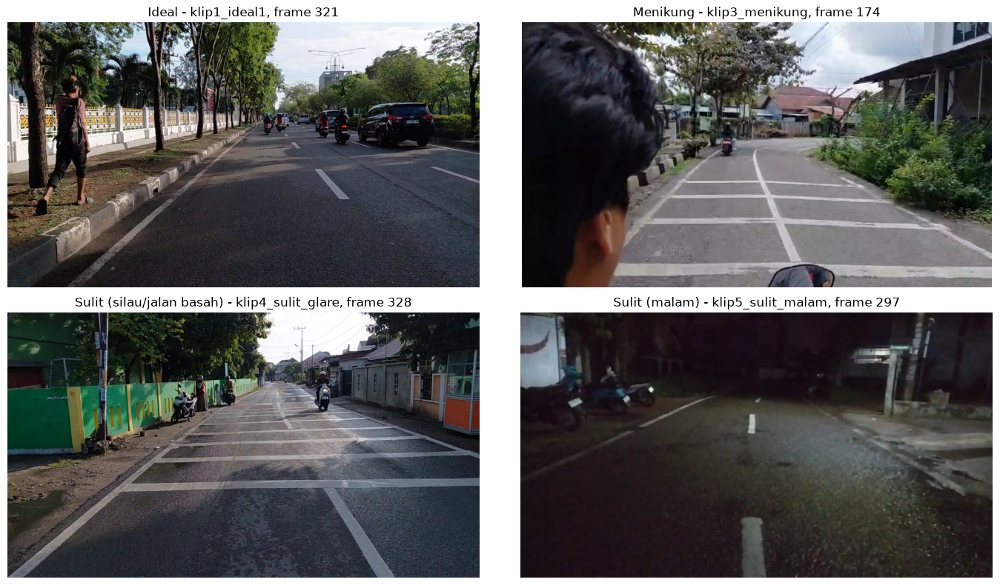

In [9]:
contoh = [("Ideal", "klip1_ideal1", 321), ("Menikung", "klip3_menikung", 174),
          ("Sulit (silau/jalan basah)", "klip4_sulit_glare", 328), ("Sulit (malam)", "klip5_sulit_malam", 297)]
fig, axs = plt.subplots(2, 2, figsize=(14, 8))
for ax, (nama, sid, fi) in zip(axs.ravel(), contoh):
    ax.imshow(rgb(FRAMES[(sid, fi)][0])); ax.set_title(f"{nama} - {sid}, frame {fi}"); ax.axis("off")
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "contoh_citra_per_kondisi.jpg"), dpi=80); plt.show()

### 3.3 Hasil kalibrasi otomatis per video
Titik hilang (lingkaran magenta), ROI trapesium (kuning), dan baris acuan (merah) **dihitung sendiri oleh program** dari tiap video. Tidak ada angka yang dimasukkan per klip.

Kalibrasi 5 video selesai dalam 18.9 detik

klip               titik_hilang  atas_roi  bawah_roi  baris_acuan  segmen_dipakai  status  
-----------------  ------------  --------  ---------  -----------  --------------  --------
klip1_ideal1       (544, 192)    0.39      0.93       0.71         2800            otomatis
klip2_ideal2       (440, 248)    0.49      0.93       0.75         5314            otomatis
klip3_menikung     (456, 224)    0.45      0.93       0.74         3430            otomatis
klip4_sulit_glare  (544, 160)    0.33      0.93       0.69         3343            otomatis
klip5_sulit_malam  (504, 128)    0.28      0.93       0.67         642             otomatis


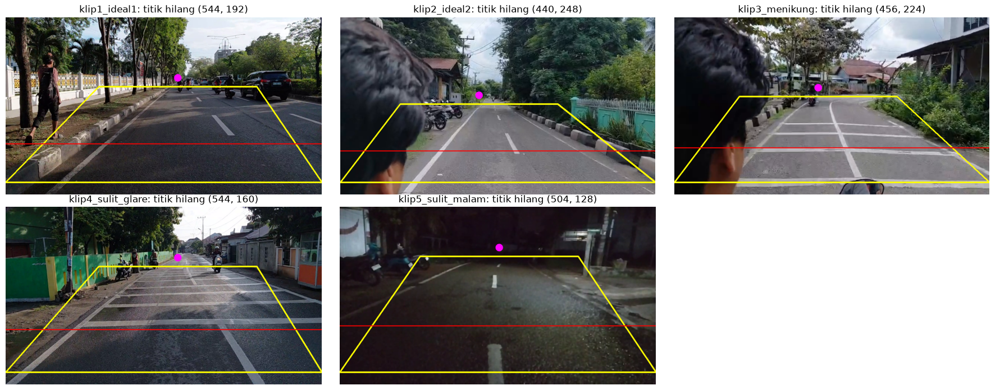

In [10]:
KAL = {}
t0 = time.perf_counter()
for sid, rel in KLIP.items():
    KAL[sid] = kalibrasi_video(cari_path_video(rel))
print(f"Kalibrasi 5 video selesai dalam {time.perf_counter() - t0:.1f} detik\n")
cetak_tabel([dict(klip=sid, titik_hilang=f"({k['vp'][0]:.0f}, {k['vp'][1]:.0f})", atas_roi=round(k["roi"][1][1], 2),
                  bawah_roi=round(k["roi"][0][1], 2), baris_acuan=round(k["y_ref"], 2), segmen_dipakai=k["n_segmen"],
                  status="otomatis" if k["otomatis"] else "cadangan") for sid, k in KAL.items()])

fig, axs = plt.subplots(2, 3, figsize=(18, 7))
for ax, (sid, fi) in zip(axs.ravel(), [("klip1_ideal1", 321), ("klip2_ideal2", 319), ("klip3_menikung", 174),
                                         ("klip4_sulit_glare", 328), ("klip5_sulit_malam", 297)]):
    frame = FRAMES[(sid, fi)][0].copy(); h, w = frame.shape[:2]; k = KAL[sid]
    pts = buat_mask_roi(frame.shape, k["roi"])[1]
    cv2.polylines(frame, [pts], True, (0, 255, 255), 3)
    cv2.line(frame, (0, int(k["y_ref"] * h)), (w, int(k["y_ref"] * h)), (0, 0, 255), 2)
    cv2.circle(frame, (int(k["vp"][0]), int(k["vp"][1])), 12, (255, 0, 255), -1)
    ax.imshow(rgb(frame)); ax.set_title(f"{sid}: titik hilang ({k['vp'][0]:.0f}, {k['vp'][1]:.0f})"); ax.axis("off")
axs.ravel()[-1].axis("off")
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "kalibrasi_roi_otomatis.jpg"), dpi=80); plt.show()

---
## Bagian 4. Pipeline Langkah demi Langkah

Urutan: **asli → grayscale → Gaussian blur → Canny → mask ROI → masker marka terang → Canny∩ROI∩terang → segmen HoughLinesP → hasil akhir**.

### Alasan pemilihan metode dan parameter
- **Resize ke sisi terpanjang 1000 px.** Video Full HD (1920×1080) menjadi sekitar 3,7× lebih sedikit piksel, sehingga proses cepat. Marka di kejauhan masih terlihat karena memakai `INTER_AREA`.
- **Grayscale.** Marka dibedakan dari aspal oleh terang-gelap. Satu kanal cukup dan lebih cepat daripada tiga kanal.
- **Gaussian blur 5×5.** Meredam butiran aspal agar tidak menjadi tepi palsu, tetapi tepi marka tetap tajam. Kernel lebih besar mulai mengaburkan marka tipis di kejauhan.
- **Canny dengan ambang otomatis (persentil 97 gradien, rasio 0,4).** Ambang tetap seperti (60, 180) disetel untuk video yang mirip dengan dataset kami. Pada video beresolusi rendah atau buram, gradien marka jauh lebih lemah dan sebagian marka hilang. Ambang dari persentil gradien menyesuaikan dengan ketajaman video. Pengaruhnya diuji di Bagian 6B.
- **Masker marka terang.** Canny juga menangkap tepi retakan, bekas ban, dan bayangan. Semua itu lebih gelap daripada sekitarnya, sedangkan marka lebih terang. Mengalikan (AND) tepi Canny dengan masker ini membuang sebagian besar tepi palsu sebelum Hough.
- **Mask ROI trapesium dari titik hilang.** Perspektif jalan membentuk trapesium yang menyempit ke titik hilang, sehingga trapesium dibentuk dari titik hilang hasil kalibrasi. Mask membuang langit, pohon, bangunan, serta kap/dasbor kendaraan.
- **HoughLinesP (`rho`=1 px, `theta`=1°, `threshold`=25, `minLineLength`=25, `maxLineGap`=60).** `minLineLength` menolak noise pendek. `maxLineGap` menyambung potongan marka putus-putus. Hough probabilistik langsung memberi segmen (x1,y1,x2,y2) sehingga mudah disaring dan diukur panjangnya.
- **Pemilihan garis kiri/kanan.** Segmen horizontal dibuang (garis kejut, zebra cross, garis henti). Segmen yang perpanjangannya tidak lewat dekat titik hilang juga dibuang. Segmen yang miring ke kanan-atas menjadi kandidat kiri. Segmen yang miring ke kiri-atas atau hampir tegak menjadi kandidat kanan, karena di Indonesia kendaraan berjalan di lajur kiri sehingga marka tengah sering berada tepat di depan kamera. Kandidat dikelompokkan menurut posisinya pada baris acuan (satu kelompok = satu garis fisik), lalu dipilih kelompok **terdekat ke kendaraan** yang marka-nya lebih terang daripada aspal di sekitarnya.
- **Smoothing antar-frame (hanya untuk video).** EMA pada parameter garis (`alpha`=0,4) dan model ditahan maksimal 6 frame bila garis hilang sesaat. Evaluasi utama di Bagian 5 dilakukan per frame **tanpa** smoothing, supaya tidak menutupi kegagalan.

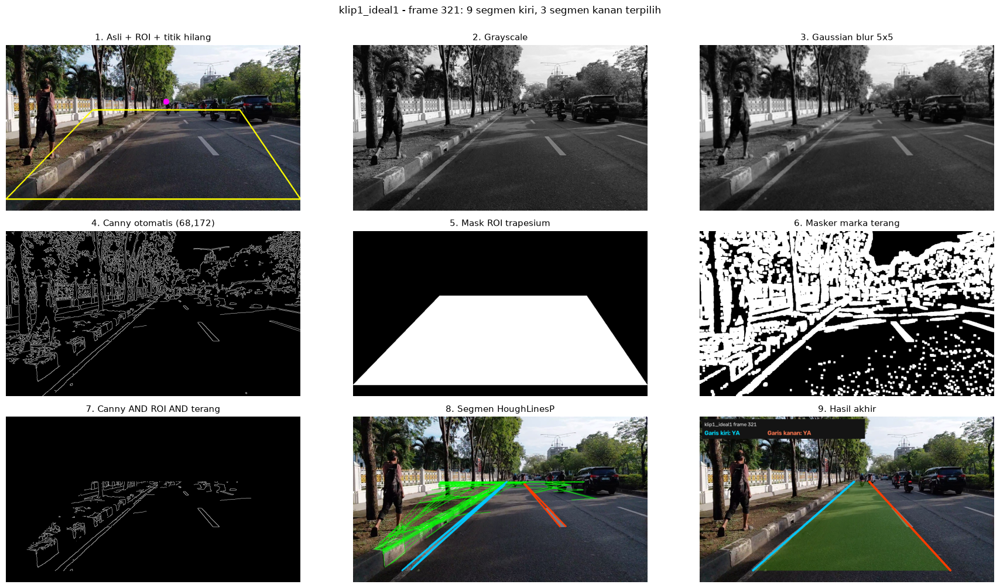

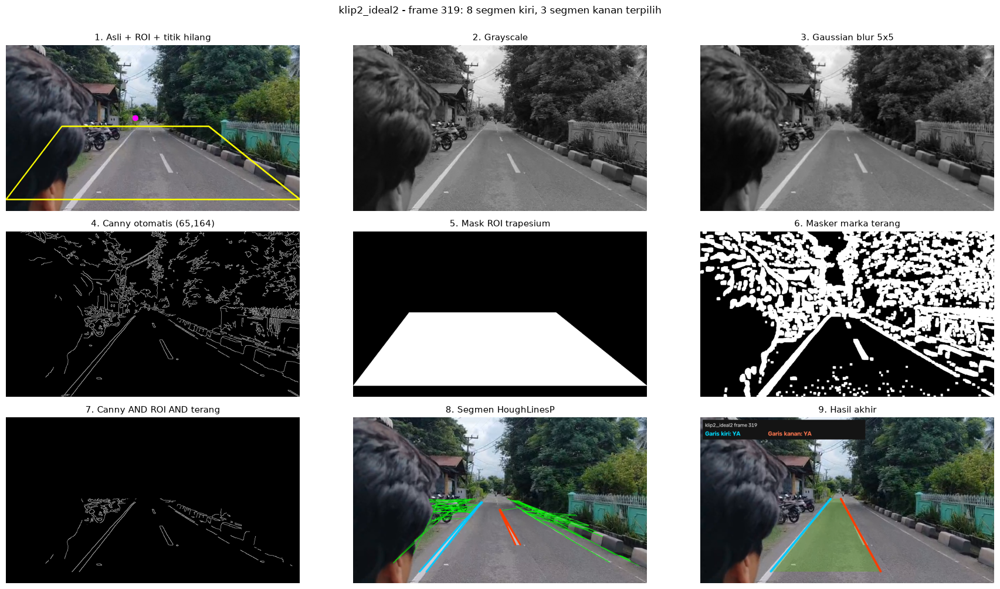

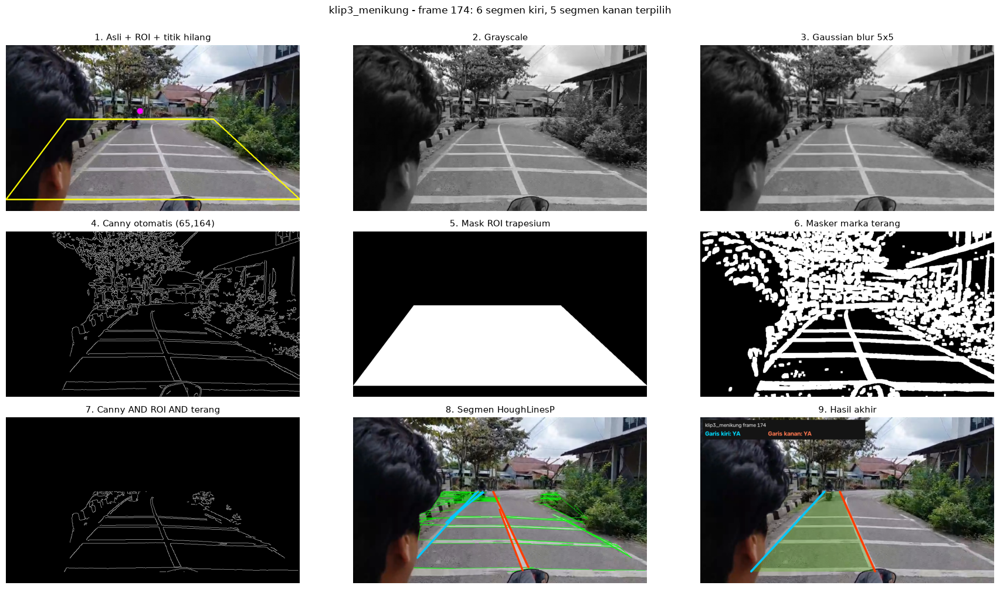

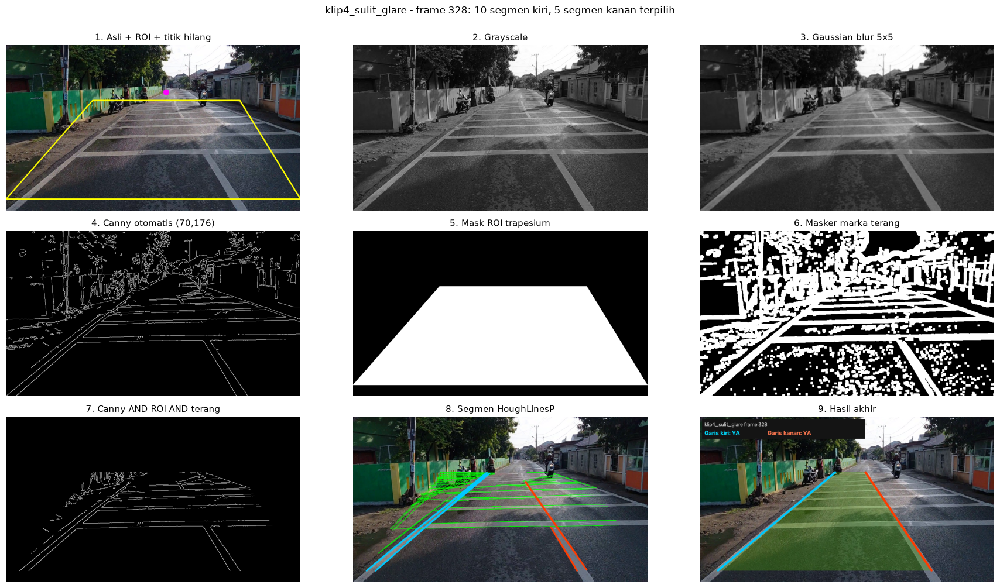

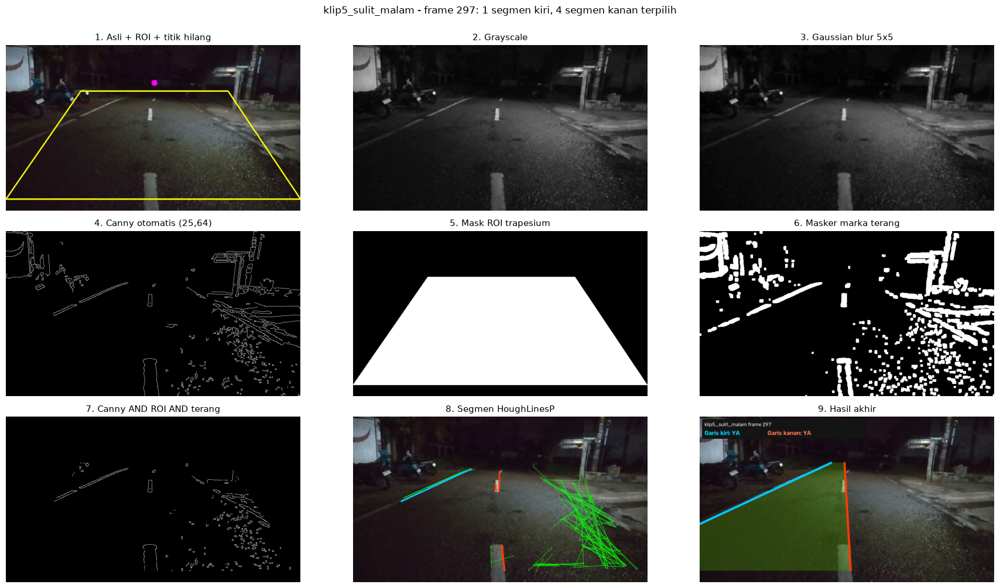

In [11]:
def langkah_pipeline(sid, fi, P=PARAM):
    frame, gray, blur = FRAMES[(sid, fi)]
    kal = KAL[sid]
    seg = segmentasi(blur, kal, P=P)
    d = deteksi(seg["roi_edges"], gray, kal, P)
    # panel Hough: semua segmen hijau tipis, segmen terpilih kiri (biru) dan kanan (merah)
    hough = frame.copy()
    if d["garis"] is not None:
        for x1, y1, x2, y2 in d["garis"].reshape(-1, 4):
            cv2.line(hough, (x1, y1), (x2, y2), (0, 255, 0), 1, cv2.LINE_AA)
    for s in d["seg_kiri"]:  cv2.line(hough, (int(s[0]), int(s[1])), (int(s[2]), int(s[3])), (255, 200, 0), 4, cv2.LINE_AA)
    for s in d["seg_kanan"]: cv2.line(hough, (int(s[0]), int(s[1])), (int(s[2]), int(s[3])), (0, 60, 255), 4, cv2.LINE_AA)
    asli = frame.copy(); cv2.polylines(asli, [seg["pts"]], True, (0, 255, 255), 3)
    cv2.circle(asli, (int(kal["vp"][0]), int(kal["vp"][1])), 10, (255, 0, 255), -1)
    akhir = gambar_hasil(frame, d["model_kiri"], d["model_kanan"], kal, f"{sid} frame {fi}")
    lo, hi = seg["canny"]
    panel = [("1. Asli + ROI + titik hilang", rgb(asli)), ("2. Grayscale", gray), ("3. Gaussian blur 5x5", blur),
             (f"4. Canny otomatis ({lo},{hi})", seg["edges"]), ("5. Mask ROI trapesium", seg["mask"]),
             ("6. Masker marka terang", seg["terang"]), ("7. Canny AND ROI AND terang", seg["roi_edges"]),
             ("8. Segmen HoughLinesP", rgb(hough)), ("9. Hasil akhir", rgb(akhir))]
    fig, axs = plt.subplots(3, 3, figsize=(18, 10))
    for ax, (jd, im) in zip(axs.ravel(), panel):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None); ax.set_title(jd, fontsize=11); ax.axis("off")
    fig.suptitle(f"{sid} - frame {fi}: {len(d['seg_kiri'])} segmen kiri, {len(d['seg_kanan'])} segmen kanan terpilih", y=1.0)
    plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "pipeline_steps", f"pipeline_{sid}.jpg"), dpi=70); plt.show()

for sid, fi in [("klip1_ideal1", 321), ("klip2_ideal2", 319), ("klip3_menikung", 174), ("klip4_sulit_glare", 328), ("klip5_sulit_malam", 297)]:
    langkah_pipeline(sid, fi)

---
## Bagian 5. Evaluasi Seluruh Dataset
Pipeline dijalankan pada **seluruh frame** kelima video dengan `VideoCapture` dan `VideoWriter` (hasil `.mp4` di `output/videos/`). Lalu hasilnya dibandingkan dengan `ground_truth.csv`.

**Kriteria benar** untuk tiap sisi (kiri/kanan) pada satu frame:
- bila ground truth `Ya`: garis harus terdeteksi dan jarak horizontal pada baris anotasi ≤ **50 px** (5% lebar frame);
- bila ground truth `Tidak`: program tidak boleh mendeteksi garis (garis dianggap terdeteksi bila memotong baris anotasi di dalam frame, minimal 20 px dari tepi).

Evaluasi utama memakai deteksi **per frame tanpa smoothing**. Hasil dari video yang sudah di-smoothing dilaporkan terpisah.

### 5.1 Memproses semua frame dan menyimpan video `.mp4`

In [12]:
RINGKASAN, PRED_VIDEO = [], {}
for sid, rel in KLIP.items():
    out_path = os.path.join(OUTPUT_DIR, "videos", f"hasil_{sid}.mp4")
    idx_gt = [r["frame_idx"] for r in GT if r["short_id"] == sid]
    r, pred = proses_video(cari_path_video(rel), out_path, KAL[sid], catat=idx_gt, label=sid)
    cek = cv2.VideoCapture(out_path); n_tulis = int(cek.get(cv2.CAP_PROP_FRAME_COUNT)); cek.release()
    r = dict(klip=sid, frame_dibaca=r["frame_dibaca"], frame_ditulis=n_tulis, **{k: v for k, v in r.items() if k not in ("frame_dibaca", "file")},
             ukuran_mb=round(os.path.getsize(out_path) / 1e6, 1))
    RINGKASAN.append(r)
    PRED_VIDEO.update({(sid, i): m for i, m in pred.items()})
    print(f"[selesai] {sid}: {r['frame_dibaca']} frame dibaca, {r['frame_ditulis']} frame ditulis -> {out_path} ({r['ukuran_mb']} MB, {r['fps_proses']} FPS proses)")
assert all(r["frame_dibaca"] == r["frame_ditulis"] for r in RINGKASAN)
assert [r["frame_dibaca"] for r in RINGKASAN] == [i["frame"] for i in INFO]
print()
cetak_tabel(RINGKASAN, ["klip", "frame_dibaca", "frame_ditulis", "ukuran", "fps_video", "garis_kiri_digambar_pct",
                        "garis_kanan_digambar_pct", "frame_menyilang_pct", "fps_proses", "ukuran_mb"])
print("\nTotal frame diproses:", sum(r["frame_dibaca"] for r in RINGKASAN))

[selesai] klip1_ideal1: 724 frame dibaca, 724 frame ditulis -> output/videos/hasil_klip1_ideal1.mp4 (91.4 MB, 22.7 FPS proses)


[selesai] klip2_ideal2: 576 frame dibaca, 576 frame ditulis -> output/videos/hasil_klip2_ideal2.mp4 (23.0 MB, 27.7 FPS proses)


[selesai] klip3_menikung: 523 frame dibaca, 523 frame ditulis -> output/videos/hasil_klip3_menikung.mp4 (21.7 MB, 36.0 FPS proses)


[selesai] klip4_sulit_glare: 741 frame dibaca, 741 frame ditulis -> output/videos/hasil_klip4_sulit_glare.mp4 (72.2 MB, 19.7 FPS proses)


[selesai] klip5_sulit_malam: 671 frame dibaca, 671 frame ditulis -> output/videos/hasil_klip5_sulit_malam.mp4 (4.9 MB, 36.1 FPS proses)

klip               frame_dibaca  frame_ditulis  ukuran    fps_video  garis_kiri_digambar_pct  garis_kanan_digambar_pct  frame_menyilang_pct  fps_proses  ukuran_mb
-----------------  ------------  -------------  --------  ---------  -----------------------  ------------------------  -------------------  ----------  ---------
klip1_ideal1       724           724            1000x562  29.9       100.0                    99.3                      10.4                 22.7        91.4     
klip2_ideal2       576           576            1000x564  29.9       100.0                    100.0                     0.90                 27.7        23.0     
klip3_menikung     523           523            1000x564  29.7       100.0                    99.4                      6.7                  36.0        21.7     
klip4_sulit_glare  741           741            

### 5.2 Perbandingan dengan ground truth: tabel per citra dan akurasi per kondisi

In [13]:
def nilai_sisi(gt_ada, gt_x, pred_x, lebar, P=PARAM):
    pred_ada = pred_x is not None and P["margin_px"] <= pred_x <= lebar - P["margin_px"]
    if gt_ada != pred_ada:
        return pred_ada, None, False
    if gt_ada:
        err = abs(pred_x - gt_x)
        return pred_ada, err, bool(err <= P["toleransi_px"])
    return pred_ada, None, True


def evaluasi_gt(P=PARAM, detektor=deteksi, canny=None):
    # Jalankan pipeline per frame (tanpa smoothing) pada 50 frame ground truth.
    baris = []
    for r in GT:
        sid, fi = r["short_id"], r["frame_idx"]
        frame, gray, blur = FRAMES[(sid, fi)]
        h, w = gray.shape
        kal = KAL[sid]
        seg = segmentasi(blur, kal, canny, P)
        d = detektor(seg["roi_edges"], gray, kal, P)
        y = r["y_ref"] * h                                  # baris tempat anotasi ground truth dicatat
        xk, xr = x_pada_baris(d["model_kiri"], y), x_pada_baris(d["model_kanan"], y)
        pk, ek, okk = nilai_sisi(r["gt_kiri"], r["left_x"], xk, w, P)
        pr, er, okr = nilai_sisi(r["gt_kanan"], r["right_x"], xr, w, P)
        baris.append(dict(klip=sid, kondisi=r["kondisi"], frame=fi,
                          gt_kiri="Ya" if r["gt_kiri"] else "Tidak", pred_kiri="Ya" if pk else "Tidak",
                          x_gt_kiri=r["left_x"], x_pred_kiri=None if xk is None else round(xk), err_kiri=ek, ok_kiri=okk,
                          gt_kanan="Ya" if r["gt_kanan"] else "Tidak", pred_kanan="Ya" if pr else "Tidak",
                          x_gt_kanan=r["right_x"], x_pred_kanan=None if xr is None else round(xr), err_kanan=er, ok_kanan=okr,
                          ok_semua=okk and okr, canny=f"{seg['canny'][0]}/{seg['canny'][1]}",
                          waktu_hough_ms=d["waktu_ms"], n_garis=d["n_garis"]))
    return baris


def rata(nilai):
    v = [x for x in nilai if x is not None]
    return float(np.mean(v)) if v else None


def bulat(x, n=1):
    return None if x is None else round(x, n)


URUTAN_KONDISI = ["Ideal", "Menikung", "Sulit"]

def ringkas_akurasi(baris):
    hasil = []
    for k in URUTAN_KONDISI + ["TOTAL"]:
        s = [b for b in baris if k == "TOTAL" or b["kondisi"] == k]
        hasil.append(dict(kondisi=k, frame=len(s),
                          akurasi_kiri=bulat(100 * rata([b["ok_kiri"] for b in s])),
                          akurasi_kanan=bulat(100 * rata([b["ok_kanan"] for b in s])),
                          akurasi_kedua_garis=bulat(100 * rata([b["ok_semua"] for b in s])),
                          benar_kedua=f"{sum(b['ok_semua'] for b in s)}/{len(s)}",
                          mae_px_kiri=bulat(rata([b["err_kiri"] for b in s])),
                          mae_px_kanan=bulat(rata([b["err_kanan"] for b in s]))))
    return hasil


HASIL = evaluasi_gt()
for i, b in enumerate(HASIL, 1):
    b["no"] = i
    b["gt (K/R)"] = f"{b['gt_kiri']}/{b['gt_kanan']}"
    b["pred (K/R)"] = f"{b['pred_kiri']}/{b['pred_kanan']}"
    b["x kiri gt->pred"] = f"{'-' if b['x_gt_kiri'] is None else int(b['x_gt_kiri'])}->{b['x_pred_kiri']}"
    b["x kanan gt->pred"] = f"{'-' if b['x_gt_kanan'] is None else int(b['x_gt_kanan'])}->{b['x_pred_kanan']}"
    b["status"] = "Sesuai" if b["ok_semua"] else "Tidak sesuai"
cetak_tabel(HASIL, ["no", "klip", "kondisi", "frame", "gt (K/R)", "pred (K/R)", "x kiri gt->pred", "x kanan gt->pred", "canny", "status"],
            "=== TABEL HASIL PER CITRA (50 frame ground truth, deteksi per frame tanpa smoothing) ===")
AKURASI = ringkas_akurasi(HASIL)
print()
cetak_tabel(AKURASI, judul="=== AKURASI PER KONDISI (%) dan galat posisi rata-rata (px) ===")

# Rincian per klip: kondisi Sulit dipisah menjadi malam (cahaya) dan jalan basah/silau
SUB_KONDISI = {"klip4_sulit_glare": "Sulit (basah/silau)", "klip5_sulit_malam": "Sulit (malam)"}
RINCI = []
for sid in KLIP:
    s = [b for b in HASIL if b["klip"] == sid]
    RINCI.append(dict(klip=sid, kondisi=SUB_KONDISI.get(sid, s[0]["kondisi"]), frame=len(s),
                      akurasi_kiri=bulat(100 * rata([b["ok_kiri"] for b in s])),
                      akurasi_kanan=bulat(100 * rata([b["ok_kanan"] for b in s])),
                      akurasi_kedua_garis=bulat(100 * rata([b["ok_semua"] for b in s])),
                      benar_kedua=f"{sum(b['ok_semua'] for b in s)}/{len(s)}"))
print()
cetak_tabel(RINCI, judul="=== RINCIAN PER KLIP (Sulit dipisah: malam dan basah/silau) ===")
simpan_csv(os.path.join(OUTPUT_DIR, "evaluasi_ground_truth.csv"), HASIL,
           ["klip", "kondisi", "frame", "gt_kiri", "pred_kiri", "x_gt_kiri", "x_pred_kiri", "err_kiri", "ok_kiri",
            "gt_kanan", "pred_kanan", "x_gt_kanan", "x_pred_kanan", "err_kanan", "ok_kanan", "ok_semua", "canny"])

=== TABEL HASIL PER CITRA (50 frame ground truth, deteksi per frame tanpa smoothing) ===
no  klip               kondisi   frame  gt (K/R)  pred (K/R)  x kiri gt->pred  x kanan gt->pred  canny   status      
--  -----------------  --------  -----  --------  ----------  ---------------  ----------------  ------  ------------
1   klip1_ideal1       Ideal     0      Ya/Ya     Ya/Ya       190->165         890->762          68/172  Tidak sesuai
2   klip1_ideal1       Ideal     80     Ya/Ya     Ya/Ya       165->172         760->737          60/152  Sesuai      
3   klip1_ideal1       Ideal     160    Ya/Ya     Ya/Ya       195->232         745->712          64/160  Sesuai      
4   klip1_ideal1       Ideal     241    Ya/Ya     Ya/Ya       300->301         790->778          65/164  Sesuai      
5   klip1_ideal1       Ideal     321    Ya/Ya     Ya/Ya       295->296         775->760          68/172  Sesuai      
6   klip1_ideal1       Ideal     401    Ya/Ya     Ya/Ya       283->274         727->7

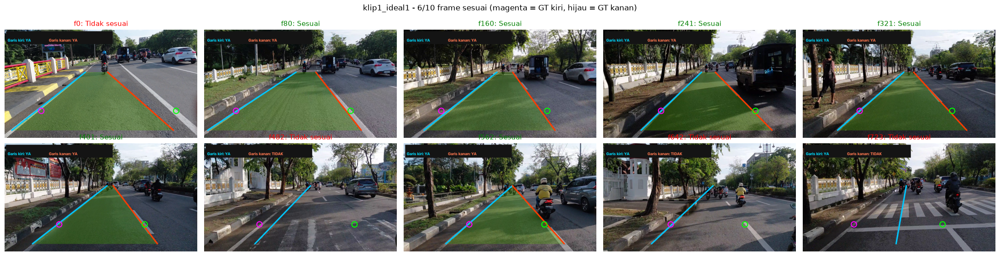

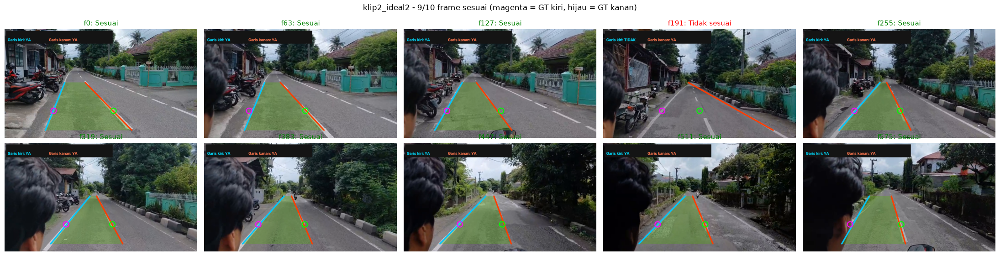

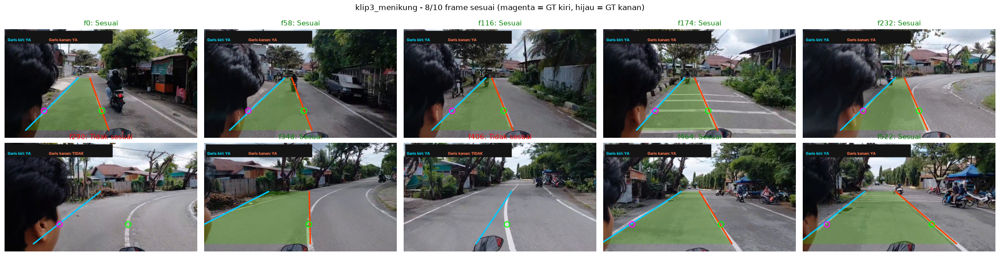

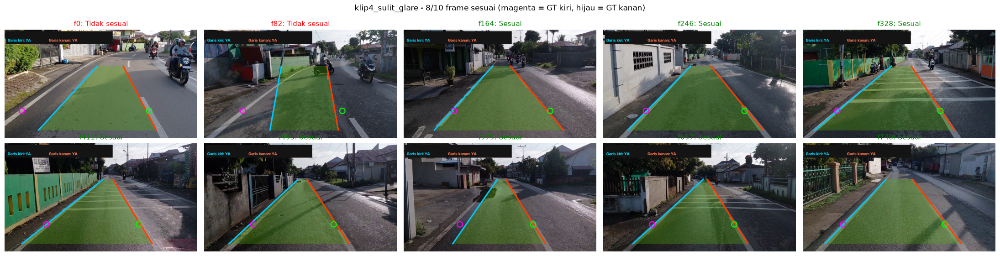

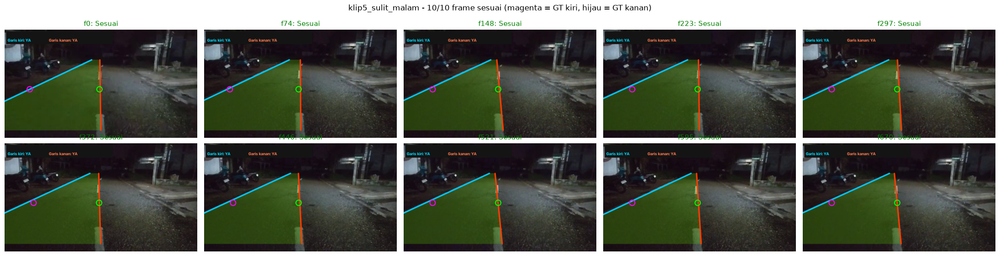

In [14]:
# Grid 10 frame ground truth per klip: lingkaran = posisi anotasi manual, garis = hasil program (tanpa smoothing)
for sid in KLIP:
    baris_k = [b for b in HASIL if b["klip"] == sid]
    fig, axs = plt.subplots(2, 5, figsize=(22, 5.6))
    for ax, b in zip(axs.ravel(), baris_k):
        r = next(g for g in GT if g["short_id"] == sid and g["frame_idx"] == b["frame"])
        frame, gray, blur = FRAMES[(sid, b["frame"])]
        seg = segmentasi(blur, KAL[sid]); d = deteksi(seg["roi_edges"], gray, KAL[sid])
        im = gambar_hasil(frame, d["model_kiri"], d["model_kanan"], KAL[sid], "")
        y = int(r["y_ref"] * gray.shape[0])
        if r["gt_kiri"]:  cv2.circle(im, (int(r["left_x"]), y), 14, (255, 0, 255), 4)
        if r["gt_kanan"]: cv2.circle(im, (int(r["right_x"]), y), 14, (0, 255, 0), 4)
        ax.imshow(rgb(im)); ax.axis("off")
        ax.set_title(f"f{b['frame']}: {b['status']}", color="green" if b["ok_semua"] else "red", fontsize=11)
    benar = sum(b["ok_semua"] for b in baris_k)
    fig.suptitle(f"{sid} - {benar}/{len(baris_k)} frame sesuai (magenta = GT kiri, hijau = GT kanan)", y=1.0)
    plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "ground_truth", f"gt_10frames_{sid}.jpg"), dpi=60); plt.show()

### 5.3 Hasil yang sama pada video akhir (dengan smoothing antar-frame)

=== AKURASI PADA VIDEO KELUARAN (dengan smoothing) ===
kondisi   frame  akurasi_kiri  akurasi_kanan  akurasi_kedua_garis  benar_kedua  mae_px_kiri  mae_px_kanan
--------  -----  ------------  -------------  -------------------  -----------  -----------  ------------
Ideal     20     90.0          80.0           80.0                 16/20        24.5         34.7        
Menikung  10     90.0          100.0          90.0                 9/10         9.0          5.8         
Sulit     20     90.0          95.0           90.0                 18/20        32.6         14.0        
TOTAL     50     90.0          90.0           86.0                 43/50        25.3         20.6        


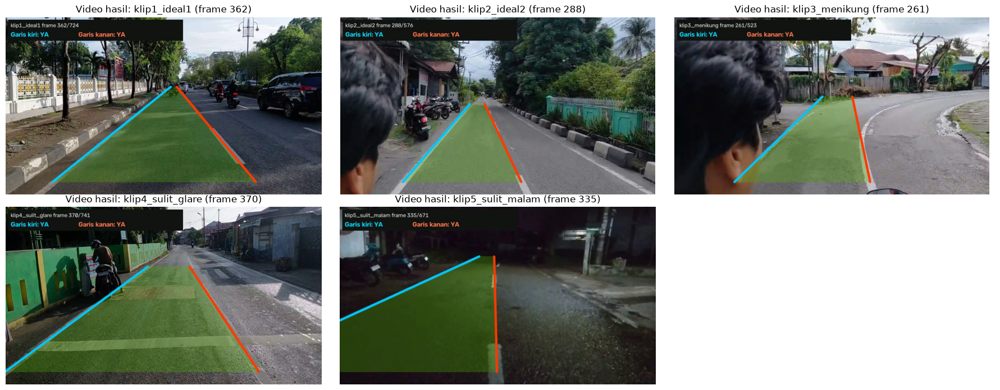

In [15]:
HASIL_V = []
for r, b in zip(GT, HASIL):
    mk, mr = PRED_VIDEO[(r["short_id"], r["frame_idx"])]
    h, w = FRAMES[(r["short_id"], r["frame_idx"])][1].shape
    y = r["y_ref"] * h
    _, ek, okk = nilai_sisi(r["gt_kiri"], r["left_x"], x_pada_baris(mk, y), w)
    _, er, okr = nilai_sisi(r["gt_kanan"], r["right_x"], x_pada_baris(mr, y), w)
    HASIL_V.append(dict(b, ok_kiri=okk, ok_kanan=okr, err_kiri=ek, err_kanan=er, ok_semua=okk and okr))
AKURASI_V = ringkas_akurasi(HASIL_V)
cetak_tabel(AKURASI_V, judul="=== AKURASI PADA VIDEO KELUARAN (dengan smoothing) ===")

# Contoh 1 frame hasil video per klip (garis kiri biru muda, kanan merah)
fig, axs = plt.subplots(2, 3, figsize=(18, 7))
for ax, sid in zip(axs.ravel(), KLIP):
    cap = cv2.VideoCapture(os.path.join(OUTPUT_DIR, "videos", f"hasil_{sid}.mp4"))
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); cap.set(cv2.CAP_PROP_POS_FRAMES, n // 2)
    ok, im = cap.read(); cap.release()
    ax.imshow(rgb(im)); ax.set_title(f"Video hasil: {sid} (frame {n // 2})"); ax.axis("off")
axs.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

### 5.4 Uji tanpa pengaturan pada video di luar 5 klip dataset
Video `WhatsApp Video 2026-10-29 at 21.01.25.mp4` di `dataset/` direkam dari **motor dengan HP posisi potret**. Setengah bawah frame tertutup dasbor, dan kamera menunduk sehingga titik hilang berada di dekat tepi atas. Kondisi ini sangat berbeda dari kelima klip dataset.

Video ini **tidak punya ground truth**, sehingga hanya dinilai secara visual. Video ini juga dipakai selama pengembangan: dari video inilah kami menemukan bahwa ambang Canny berbasis median kecerahan gagal pada video buram, lalu menggantinya dengan ambang berbasis gradien. Jadi video ini **bukan data uji yang sepenuhnya bersih**. Bagian ini hanya menunjukkan bahwa pipeline yang sama berjalan tanpa mengubah satu angka pun.

Titik hilang otomatis: (158, 8) | ROI y 0.06-0.57
175 frame (750x1000) -> output/videos/hasil_uji_motor_tanpa_gt.mp4 | garis kiri digambar 97.7%, kanan 94.9% (bukan akurasi)


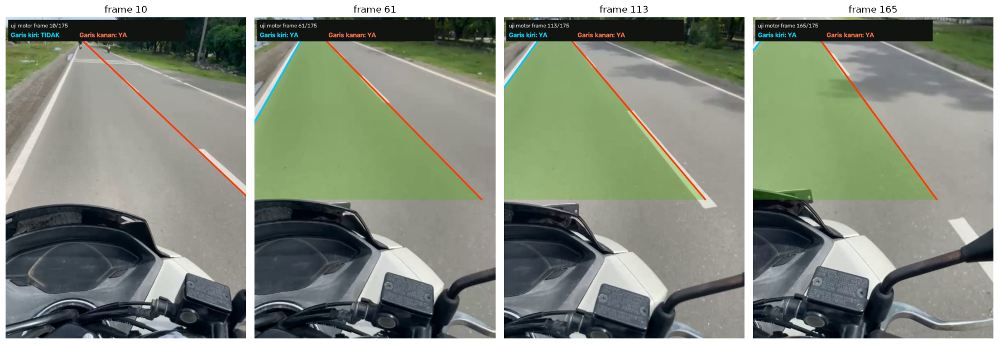

In [16]:
VIDEO_UJI = cari_path_video("WhatsApp Video 2026-10-29 at 21.01.25.mp4")
if os.path.exists(VIDEO_UJI):
    out_uji = os.path.join(OUTPUT_DIR, "videos", "hasil_uji_motor_tanpa_gt.mp4")
    kal_uji = kalibrasi_video(VIDEO_UJI)
    r_uji, _ = proses_video(VIDEO_UJI, out_uji, kal_uji, label="uji motor")
    print(f"Titik hilang otomatis: ({kal_uji['vp'][0]:.0f}, {kal_uji['vp'][1]:.0f}) | ROI y {kal_uji['roi'][1][1]:.2f}-{kal_uji['roi'][0][1]:.2f}")
    print(f"{r_uji['frame_dibaca']} frame ({r_uji['ukuran']}) -> {out_uji} | garis kiri digambar {r_uji['garis_kiri_digambar_pct']}%, "
          f"kanan {r_uji['garis_kanan_digambar_pct']}% (bukan akurasi)")
    cap = cv2.VideoCapture(out_uji); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fig, axs = plt.subplots(1, 4, figsize=(18, 6.4))
    for ax, fi in zip(axs, np.linspace(10, n - 10, 4).astype(int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(fi)); ok, im = cap.read()
        ax.imshow(rgb(im)); ax.set_title(f"frame {fi}"); ax.axis("off")
    cap.release()
    plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "uji_video_motor.jpg"), dpi=70); plt.show()
else:
    print("Video uji tidak ditemukan, bagian ini dilewati.")

---
## Bagian 6. Eksperimen Pembanding
Dua eksperimen dijalankan pada **50 frame ground truth** dengan kriteria yang sama seperti Bagian 5 (per frame, tanpa smoothing):
- **6A.** `cv2.HoughLines` (Hough standar) vs `cv2.HoughLinesP` (Hough probabilistik).
- **6B.** Pengaruh ambang bawah/atas `cv2.Canny`: beberapa pasangan ambang tetap dibandingkan dengan ambang otomatis.

Pada 6A, edge map, ROI, pemilihan garis kiri/kanan, dan fitting dibuat **identik**. Satu-satunya yang berubah adalah detektor garisnya.

### 6A. `HoughLines` vs `HoughLinesP`

In [17]:
def buat_detektor_hough_standar(thr):
    # HoughLines mengembalikan (rho, theta) garis tak hingga. Dipotong pada tinggi ROI menjadi segmen
    # agar bisa melewati tahap pemilihan dan fitting yang sama dengan HoughLinesP.
    def detektor(roi_edges, gray, kal, P=PARAM):
        h = gray.shape[0]
        roi, y_ref = kal["roi"], kal["y_ref"] * h
        y_atas, y_bawah = roi[1][1] * h, roi[0][1] * h
        t0 = time.perf_counter()
        garis = cv2.HoughLines(roi_edges, P["hough_rho"], P["hough_theta"], thr)
        waktu_ms = (time.perf_counter() - t0) * 1000
        segmen = []
        if garis is not None:
            for rho, theta in garis.reshape(-1, 2)[:300]:
                a, b = np.cos(theta), np.sin(theta)
                if abs(a) < 1e-3:                 # garis horizontal: tidak bisa ditulis x = f(y)
                    continue
                segmen.append((float(np.clip((rho - y_bawah * b) / a, -5000, 5000)), y_bawah,
                               float(np.clip((rho - y_atas * b) / a, -5000, 5000)), y_atas))
        arr = np.array(segmen, np.float32).reshape(-1, 1, 4) if segmen else None
        kiri, kanan = pilih_garis(arr, gray, y_ref, kal["vp"], P)
        mk, mr = fit_garis(kiri), fit_garis(kanan)
        mk, mr, silang = konsistensi(mk, mr, kiri, kanan, y_ref, y_atas, y_bawah, P)
        return dict(garis=arr, seg_kiri=kiri, seg_kanan=kanan, model_kiri=mk, model_kanan=mr, menyilang=silang,
                    waktu_ms=waktu_ms, n_garis=0 if garis is None else len(garis))
    return detektor


TABEL_HOUGH, DETEKTOR = [], {}
konfigurasi = [("HoughLinesP", "threshold=25, minLen=25, gap=60", deteksi)] + \
              [("HoughLines", f"threshold={t}", buat_detektor_hough_standar(t)) for t in (60, 100, 150)]
for nama, par, det in konfigurasi:
    h = evaluasi_gt(detektor=det)
    DETEKTOR[(nama, par)] = det
    TABEL_HOUGH.append({"metode": nama, "parameter": par,
                        "akurasi_kiri_%": bulat(100 * rata([b["ok_kiri"] for b in h])),
                        "akurasi_kanan_%": bulat(100 * rata([b["ok_kanan"] for b in h])),
                        "akurasi_kedua_garis_%": bulat(100 * rata([b["ok_semua"] for b in h])),
                        "mae_px_kiri": bulat(rata([b["err_kiri"] for b in h])), "mae_px_kanan": bulat(rata([b["err_kanan"] for b in h])),
                        "garis_mentah_per_frame": bulat(rata([b["n_garis"] for b in h])),
                        "waktu_hough_ms": bulat(rata([b["waktu_hough_ms"] for b in h]), 2)})
cetak_tabel(TABEL_HOUGH)
simpan_csv(os.path.join(OUTPUT_DIR, "eksperimen_hough_vs_houghp.csv"), TABEL_HOUGH)

metode       parameter                        akurasi_kiri_%  akurasi_kanan_%  akurasi_kedua_garis_%  mae_px_kiri  mae_px_kanan  garis_mentah_per_frame  waktu_hough_ms
-----------  -------------------------------  --------------  ---------------  ---------------------  -----------  ------------  ----------------------  --------------
HoughLinesP  threshold=25, minLen=25, gap=60  88.0            86.0             82.0                   26.5         16.0          93.1                    2.7           
HoughLines   threshold=60                     76.0            60.0             44.0                   36.8         54.2          114.6                   3.2           
HoughLines   threshold=100                    78.0            40.0             32.0                   17.5         89.6          14.8                    3.2           
HoughLines   threshold=150                    62.0            20.0             14.0                   10.4         121.1         3.9                     3.1    

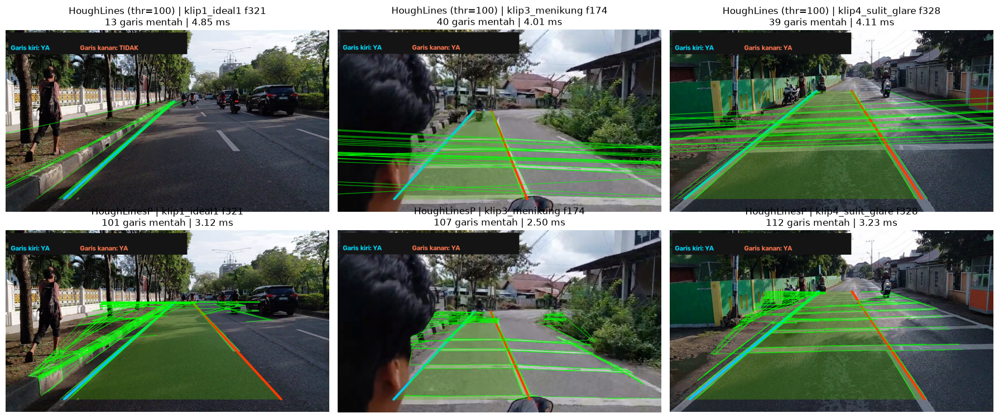

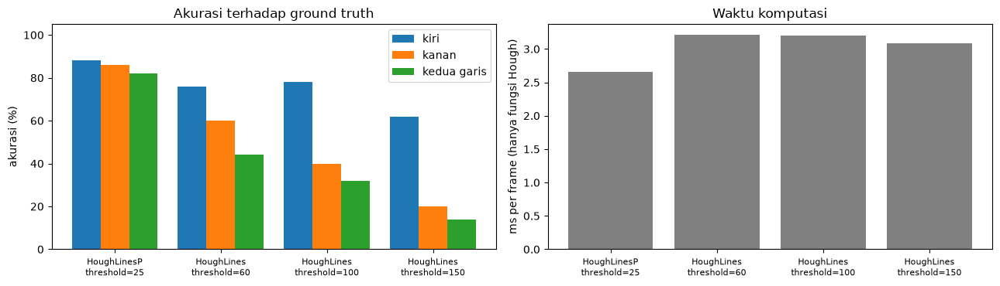

In [18]:
# Visualisasi: hasil HoughLines (atas) vs HoughLinesP (bawah) pada 3 frame
det_std = DETEKTOR[("HoughLines", "threshold=100")]
frame_uji = [("klip1_ideal1", 321), ("klip3_menikung", 174), ("klip4_sulit_glare", 328)]
fig, axs = plt.subplots(2, 3, figsize=(18, 7.5))
for j, (sid, fi) in enumerate(frame_uji):
    frame, gray, blur = FRAMES[(sid, fi)]
    seg = segmentasi(blur, KAL[sid])
    for i, (nama, det) in enumerate([("HoughLines (thr=100)", det_std), ("HoughLinesP", deteksi)]):
        d = det(seg["roi_edges"], gray, KAL[sid], PARAM)
        im = gambar_hasil(frame, d["model_kiri"], d["model_kanan"], KAL[sid], "")
        if d["garis"] is not None:
            for x1, y1, x2, y2 in d["garis"].reshape(-1, 4)[:150]:
                cv2.line(im, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 1, cv2.LINE_AA)
        axs[i, j].imshow(rgb(im)); axs[i, j].axis("off")
        axs[i, j].set_title(f"{nama} | {sid} f{fi}\n{d['n_garis']} garis mentah | {d['waktu_ms']:.2f} ms")
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "experiments", "hough_comparison.jpg"), dpi=70); plt.show()

# Grafik akurasi dan waktu
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
lab = [f"{t['metode']}\n{t['parameter'].split(',')[0]}" for t in TABEL_HOUGH]
x = np.arange(len(lab)); lebar = 0.27
axs[0].bar(x - lebar, [t["akurasi_kiri_%"] for t in TABEL_HOUGH], lebar, label="kiri")
axs[0].bar(x, [t["akurasi_kanan_%"] for t in TABEL_HOUGH], lebar, label="kanan")
axs[0].bar(x + lebar, [t["akurasi_kedua_garis_%"] for t in TABEL_HOUGH], lebar, label="kedua garis")
axs[0].set_xticks(x); axs[0].set_xticklabels(lab, fontsize=8); axs[0].set_ylabel("akurasi (%)"); axs[0].set_ylim(0, 105); axs[0].legend(); axs[0].set_title("Akurasi terhadap ground truth")
axs[1].bar(x, [t["waktu_hough_ms"] for t in TABEL_HOUGH], color="gray"); axs[1].set_xticks(x); axs[1].set_xticklabels(lab, fontsize=8)
axs[1].set_ylabel("ms per frame (hanya fungsi Hough)"); axs[1].set_title("Waktu komputasi")
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "experiments", "grafik_hough.png"), dpi=80); plt.show()

### 6B. Pengaruh ambang bawah/atas `cv2.Canny`
Tujuh pasangan ambang **tetap** dibandingkan dengan ambang **otomatis** (persentil 97 gradien, rasio 0,4) yang dipakai pipeline. Bagian lain pipeline dibuat sama.

canny      akurasi_kiri_%  akurasi_kanan_%  kedua_Ideal_%  kedua_Menikung_%  kedua_Sulit_%  kedua_total_%
---------  --------------  ---------------  -------------  ----------------  -------------  -------------
(20,60)    82.0            78.0             75.0           90.0              60.0           72.0         
(30,90)    84.0            80.0             70.0           80.0              75.0           74.0         
(40,120)   82.0            82.0             70.0           80.0              70.0           72.0         
(50,150)   88.0            90.0             80.0           90.0              80.0           82.0         
(60,180)   90.0            88.0             75.0           90.0              90.0           84.0         
(80,240)   70.0            62.0             35.0           80.0              35.0           44.0         
(100,200)  86.0            78.0             55.0           90.0              75.0           70.0         
otomatis   88.0            86.0             75

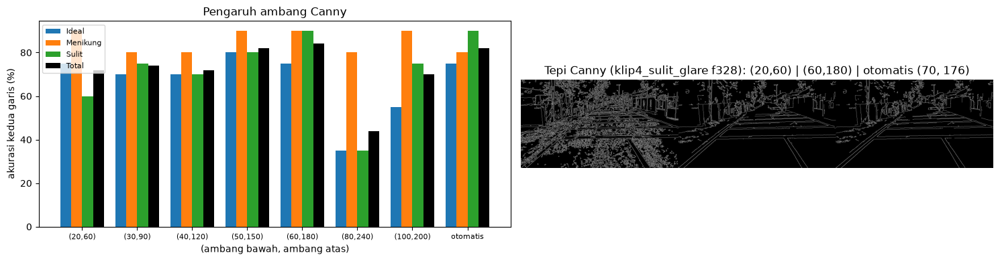

In [19]:
PASANGAN = [(20, 60), (30, 90), (40, 120), (50, 150), (60, 180), (80, 240), (100, 200), None]   # None = otomatis
TABEL_CANNY = []
for pas in PASANGAN:
    h = evaluasi_gt(canny=pas)
    r = {"canny": "otomatis" if pas is None else f"({pas[0]},{pas[1]})",
         "akurasi_kiri_%": bulat(100 * rata([b["ok_kiri"] for b in h])), "akurasi_kanan_%": bulat(100 * rata([b["ok_kanan"] for b in h]))}
    for k in URUTAN_KONDISI:
        r[f"kedua_{k}_%"] = bulat(100 * rata([b["ok_semua"] for b in h if b["kondisi"] == k]))
    r["kedua_total_%"] = bulat(100 * rata([b["ok_semua"] for b in h]))
    TABEL_CANNY.append(r)
cetak_tabel(TABEL_CANNY)
simpan_csv(os.path.join(OUTPUT_DIR, "eksperimen_canny.csv"), TABEL_CANNY)

fig, axs = plt.subplots(1, 2, figsize=(15, 4))
x = np.arange(len(TABEL_CANNY)); lebar = 0.2
for i, k in enumerate(URUTAN_KONDISI):
    axs[0].bar(x + (i - 1.5) * lebar, [t[f"kedua_{k}_%"] for t in TABEL_CANNY], lebar, label=k)
axs[0].bar(x + 1.5 * lebar, [t["kedua_total_%"] for t in TABEL_CANNY], lebar, label="Total", color="black")
axs[0].set_xticks(x); axs[0].set_xticklabels([t["canny"] for t in TABEL_CANNY], fontsize=8); axs[0].set_xlabel("(ambang bawah, ambang atas)")
axs[0].set_ylabel("akurasi kedua garis (%)"); axs[0].legend(fontsize=8); axs[0].set_title("Pengaruh ambang Canny")
sid, fi = "klip4_sulit_glare", 328
frame, gray, blur = FRAMES[(sid, fi)]
mask = buat_mask_roi(blur.shape, KAL[sid]["roi"])[0]
oto = ambang_canny_otomatis(blur, mask)
tiga = [cv2.Canny(blur, lo, hi) for lo, hi in [(20, 60), (60, 180), oto]]
axs[1].imshow(np.hstack([cv2.resize(t, (500, 281)) for t in tiga]), cmap="gray"); axs[1].axis("off")
axs[1].set_title(f"Tepi Canny ({sid} f{fi}): (20,60) | (60,180) | otomatis {oto}")
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "experiments", "grafik_canny.png"), dpi=80); plt.show()

**Mengapa ambang otomatis, padahal (60,180) sedikit lebih baik di dataset ini?** Ambang (60,180) dipilih dengan melihat 50 frame yang sama, jadi wajar bila unggul di sini. Sel di bawah menguji tiga cara pada video motor beresolusi rendah dari Bagian 5.4 (setiap frame ke-3): ambang tetap (60,180), aturan median kecerahan (`0,67×median`, `1,33×median`, cara adaptif yang kami coba lebih dulu), dan ambang otomatis dari persentil gradien. Video ini tidak punya ground truth, jadi yang dibandingkan hanya persentase frame yang garisnya tergambar, ditambah pemeriksaan visual.

Video motor (tanpa ground truth), setiap frame ke-3, tanpa smoothing:
ambang Canny        rata2 ambang  garis kiri tergambar %  garis kanan tergambar %
------------------  ------------  ----------------------  -----------------------
tetap (60,180)      (60,180)      68                      98                     
median kecerahan    (109,218)     32                      86                     
otomatis (gradien)  (25,64)       93                      92                     


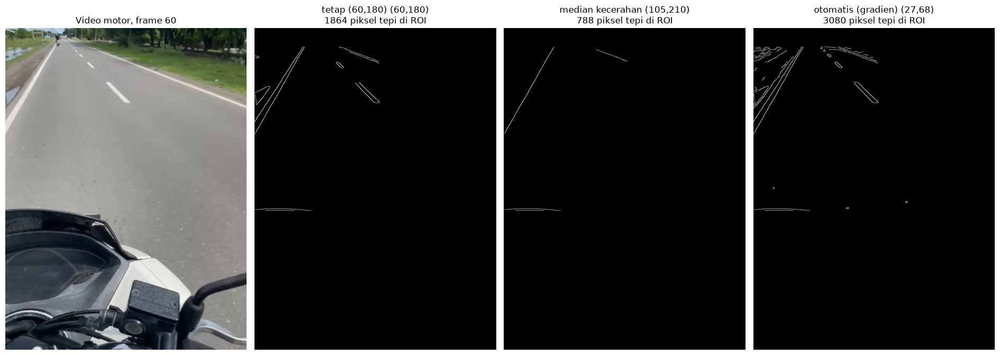

In [20]:
def ambang_median(blur, mask):
    m = float(np.median(blur[mask > 0]))
    return int(max(15, 0.67 * m)), int(max(30, 1.33 * m))

if os.path.exists(VIDEO_UJI):
    cap = cv2.VideoCapture(VIDEO_UJI); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    VARIAN = {"tetap (60,180)": lambda b, m: (60, 180), "median kecerahan": ambang_median, "otomatis (gradien)": None}
    tabel = []
    for nama, fn in VARIAN.items():
        nk = nr = m_ = 0; amb = []
        for fi in range(0, n, 3):
            cap.set(cv2.CAP_PROP_POS_FRAMES, fi); ok, raw = cap.read()
            if not ok: break
            frame, gray, blur = praproses(raw)
            mask = buat_mask_roi(blur.shape, kal_uji["roi"])[0]
            seg = segmentasi(blur, kal_uji, None if fn is None else fn(blur, mask))
            d = deteksi(seg["roi_edges"], gray, kal_uji)
            nk += d["model_kiri"] is not None; nr += d["model_kanan"] is not None; m_ += 1; amb.append(seg["canny"])
        med = np.median(np.array(amb), axis=0).astype(int)
        tabel.append({"ambang Canny": nama, "rata2 ambang": f"({med[0]},{med[1]})",
                      "garis kiri tergambar %": round(100 * nk / m_), "garis kanan tergambar %": round(100 * nr / m_)})
    cetak_tabel(tabel, judul="Video motor (tanpa ground truth), setiap frame ke-3, tanpa smoothing:")

    cap.set(cv2.CAP_PROP_POS_FRAMES, 60); ok, raw = cap.read(); cap.release()
    frame, gray, blur = praproses(raw)
    mask = buat_mask_roi(blur.shape, kal_uji["roi"])[0]
    fig, axs = plt.subplots(1, 4, figsize=(19, 6.5))
    axs[0].imshow(rgb(frame)); axs[0].set_title("Video motor, frame 60")
    for ax, (nama, fn) in zip(axs[1:], VARIAN.items()):
        lo, hi = ambang_canny_otomatis(blur, mask) if fn is None else fn(blur, mask)
        e = cv2.bitwise_and(cv2.Canny(blur, lo, hi), mask)
        ax.imshow(e, cmap="gray"); ax.set_title(f"{nama} ({lo},{hi})\n{int((e > 0).sum())} piksel tepi di ROI")
    for ax in axs: ax.axis("off")
    plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "experiments", "canny_video_motor.jpg"), dpi=70); plt.show()

Pada video motor ini, aturan median kecerahan memberi ambang terlalu tinggi (sekitar 109/218), karena aspalnya terang sementara gradien marka lemah (video buram). Akibatnya garis kiri hanya tergambar di sekitar sepertiga frame. Ambang tetap (60,180) lebih baik tetapi masih kehilangan garis kiri di sekitar sepertiga frame. Ambang otomatis dari gradien turun sendiri ke sekitar (25,64) dan menggambar kedua garis di lebih dari 90% frame. Jadi kami memilih ambang otomatis: di dataset hanya kalah 1 frame dari ambang tetap terbaik, tetapi tidak bergantung pada angka yang disetel untuk video tertentu.

---
## Bagian 7. Analisis Kegagalan
Contoh di bawah diambil dari frame yang **tidak sesuai** dengan ground truth pada Bagian 5. Pada gambar: lingkaran **magenta** = posisi garis kiri menurut ground truth, lingkaran **hijau** = posisi garis kanan menurut ground truth, garis **biru muda/merah** = segmen kiri/kanan yang dipilih program, garis hijau tipis = semua segmen HoughLinesP.

Frame gagal yang ditampilkan: [('klip1_ideal1', 0), ('klip1_ideal1', 723), ('klip2_ideal2', 191), ('klip3_menikung', 406), ('klip4_sulit_glare', 0), ('klip4_sulit_glare', 82)]
Semua frame gagal: [('klip1_ideal1', 0), ('klip1_ideal1', 482), ('klip1_ideal1', 642), ('klip1_ideal1', 723), ('klip2_ideal2', 191), ('klip3_menikung', 290), ('klip3_menikung', 406), ('klip4_sulit_glare', 0), ('klip4_sulit_glare', 82)]


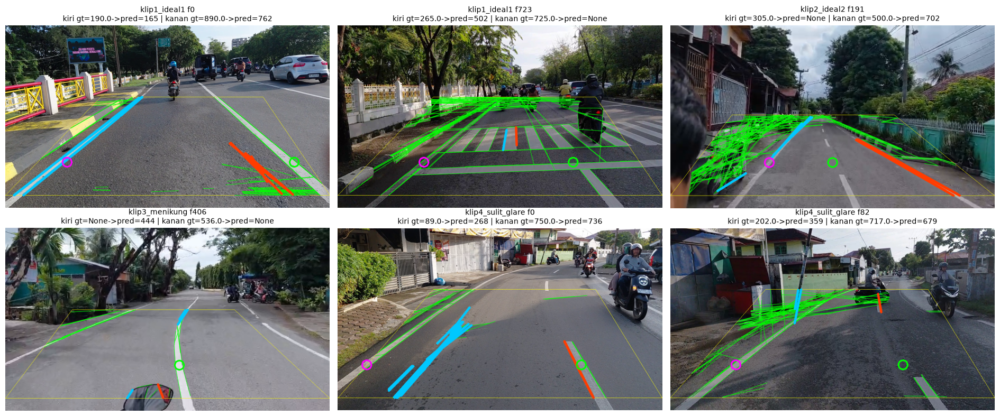

In [21]:
# 6 dari 9 frame gagal, dipilih agar mewakili penyebab yang berbeda (daftar lengkap dicetak di bawah)
KASUS_GAGAL = [("klip1_ideal1", 0), ("klip1_ideal1", 723), ("klip2_ideal2", 191),
               ("klip3_menikung", 406), ("klip4_sulit_glare", 0), ("klip4_sulit_glare", 82)]

print("Frame gagal yang ditampilkan:", KASUS_GAGAL)
print("Semua frame gagal:", [(b["klip"], b["frame"]) for b in HASIL if not b["ok_semua"]])
fig, axs = plt.subplots(2, 3, figsize=(19, 8))
for ax, (sid, fi) in zip(axs.ravel(), KASUS_GAGAL):
    frame, gray, blur = FRAMES[(sid, fi)]
    kal = KAL[sid]
    seg = segmentasi(blur, kal)
    d = deteksi(seg["roi_edges"], gray, kal)
    im = frame.copy()
    cv2.polylines(im, [seg["pts"]], True, (0, 255, 255), 1)
    if d["garis"] is not None:
        for x1, y1, x2, y2 in d["garis"].reshape(-1, 4): cv2.line(im, (x1, y1), (x2, y2), (0, 255, 0), 1, cv2.LINE_AA)
    for s in d["seg_kiri"]:  cv2.line(im, (int(s[0]), int(s[1])), (int(s[2]), int(s[3])), (255, 200, 0), 5, cv2.LINE_AA)
    for s in d["seg_kanan"]: cv2.line(im, (int(s[0]), int(s[1])), (int(s[2]), int(s[3])), (0, 60, 255), 5, cv2.LINE_AA)
    r = next(g for g in GT if g["short_id"] == sid and g["frame_idx"] == fi)
    y = int(r["y_ref"] * gray.shape[0])
    if r["gt_kiri"]:  cv2.circle(im, (int(r["left_x"]), y), 14, (255, 0, 255), 4)
    if r["gt_kanan"]: cv2.circle(im, (int(r["right_x"]), y), 14, (0, 255, 0), 4)
    b = next(b for b in HASIL if b["klip"] == sid and b["frame"] == fi)
    ax.imshow(rgb(im)); ax.axis("off")
    ax.set_title(f"{sid} f{fi}\nkiri gt={b['x_gt_kiri']}->pred={b['x_pred_kiri']} | kanan gt={b['x_gt_kanan']}->pred={b['x_pred_kanan']}", fontsize=10)
for ax in axs.ravel()[len(KASUS_GAGAL):]:
    ax.axis("off")
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "analisis_kegagalan.jpg"), dpi=70); plt.show()

### Penjelasan penyebab kegagalan
Dari 50 frame, 9 frame tidak sesuai: klip1 frame 0, 482, 642, 723; klip2 frame 191; klip3 frame 290, 406; klip4 frame 0, 82.

1. **klip1 frame 0 (garis kanan tebal di tepi frame).** Marka kanan menerus berada jauh di kanan (x≈890). Aturan "pilih garis terdekat ke kendaraan" malah memilih segmen pendek dari bekas ban/tambalan aspal yang lebih dekat ke tengah (x≈762). Segmen itu lolos karena sedikit lebih terang daripada aspal di sekitarnya.
2. **klip1 frame 482, 642, dan 723 (zebra cross dan garis henti).** Strip zebra cross yang tegak punya tepi lurus, sangat kontras, dan arahnya menuju titik hilang, persis seperti marka. Strip itu terpilih sebagai garis kiri dan/atau kanan. Kedua garis lalu saling menyilang, sehingga pemeriksaan geometri membuang salah satunya. Filter segmen horizontal hanya membuang garis henti, bukan strip yang tegak.
3. **klip2 frame 191 (objek di tepi kiri dan kanan).** Motor parkir dan kepala pengendara menghasilkan banyak segmen di kiri. Di kanan, tepi trotoar/pagar yang panjang (x≈702) mengalahkan marka tengah putus-putus yang pendek. Garis kiri dan kanan yang terpilih menyilang, sehingga garis kiri dibuang.
4. **klip3 frame 406 (tikungan, garis kiri memang tidak terlihat).** Menurut ground truth, garis kiri tidak terlihat. Program memilih bagian atas marka tengah yang melengkung sebagai garis kiri. Sementara itu marka tengah yang sama (seharusnya garis kanan) dibuang karena garis lurus tidak bisa mengikuti lengkungnya. Hal yang sama terjadi pada klip3 frame 290. **Fitting garis lurus tidak cocok untuk tikungan tajam.**
5. **klip4 frame 0 (garis tepi kiri jauh di kiri, banyak tambalan aspal).** Garis tepi kiri (x≈89) berada di sudut kiri bawah. Tambalan aspal dan pantulan cahaya yang lebih terang di tengah lajur (x≈268) lebih dekat ke kendaraan sehingga terpilih.
6. **klip4 frame 82 (jalan berbelok, tiang dan pengendara lain).** Jalan mulai berbelok sehingga marka tidak lagi mengarah ke titik hilang hasil kalibrasi dan terbuang. Yang tersisa dan lolos adalah tepi tiang di kiri (garis tegak terang) dan bagian motor di kanan.

**Pola umum:** kegagalan muncul ketika (a) ada objek lain yang bergaris lurus, terang, dan mengarah ke titik hilang (zebra cross, trotoar, tiang, tambalan aspal), (b) marka tipis, pendek, atau jauh di tepi frame, atau (c) jalan melengkung sehingga marka tidak lurus dan tidak mengarah ke titik hilang yang tetap. Perbaikan yang mungkin: fitting kurva (polinomial derajat 2), titik hilang yang diperbarui per frame saat menikung, dan penolakan pola berulang seperti zebra cross.

---
## Bagian 8. Kesimpulan

Ringkasan angka utama (dihitung ulang dari hasil di atas):
- Video hasil: 5 file .mp4, total 3235 frame ditulis = 3235 frame dataset.
- Akurasi per frame (50 frame GT, tanpa smoothing): kiri 88%, kanan 86%, kedua garis 82% (41/50).
  Ideal    : kiri 85% | kanan 75% | kedua 75%  (n=20)
  Menikung : kiri 90% | kanan 80% | kedua 80%  (n=10)
  Sulit    : kiri 90% | kanan 100% | kedua 90%  (n=20)
- Pada video (dengan smoothing): kedua garis 86% (43/50).
- Frame dengan garis kiri-kanan menyilang/tidak masuk akal (semua frame): klip1_ideal1 10%, klip2_ideal2 1%, klip3_menikung 7%, klip4_sulit_glare 6%, klip5_sulit_malam 0%
- HoughLinesP 82% vs HoughLines terbaik 44%.
- Canny otomatis 82% | ambang tetap terbaik (60,180) 84%, terburuk 44%.


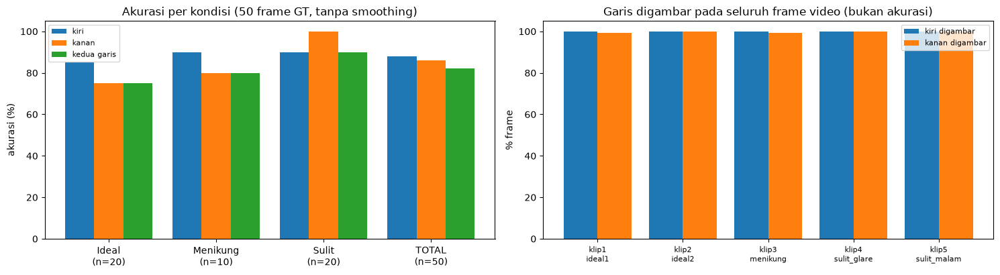

In [22]:
tot, tot_v = AKURASI[-1], AKURASI_V[-1]
print("Ringkasan angka utama (dihitung ulang dari hasil di atas):")
print(f"- Video hasil: {len(RINGKASAN)} file .mp4, total {sum(r['frame_ditulis'] for r in RINGKASAN)} frame ditulis = {sum(i['frame'] for i in INFO)} frame dataset.")
print(f"- Akurasi per frame (50 frame GT, tanpa smoothing): kiri {tot['akurasi_kiri']:.0f}%, kanan {tot['akurasi_kanan']:.0f}%, kedua garis {tot['akurasi_kedua_garis']:.0f}% ({tot['benar_kedua']}).")
for a in AKURASI[:-1]:
    print(f"  {a['kondisi']:9s}: kiri {a['akurasi_kiri']:.0f}% | kanan {a['akurasi_kanan']:.0f}% | kedua {a['akurasi_kedua_garis']:.0f}%  (n={a['frame']})")
print(f"- Pada video (dengan smoothing): kedua garis {tot_v['akurasi_kedua_garis']:.0f}% ({tot_v['benar_kedua']}).")
print("- Frame dengan garis kiri-kanan menyilang/tidak masuk akal (semua frame): " + ", ".join(f"{r['klip']} {r['frame_menyilang_pct']:.0f}%" for r in RINGKASAN))
print(f"- HoughLinesP {TABEL_HOUGH[0]['akurasi_kedua_garis_%']:.0f}% vs HoughLines terbaik {max(t['akurasi_kedua_garis_%'] for t in TABEL_HOUGH[1:]):.0f}%.")
tetap = [t for t in TABEL_CANNY if t["canny"] != "otomatis"]
terbaik = max(tetap, key=lambda t: t["kedua_total_%"])
print(f"- Canny otomatis {TABEL_CANNY[-1]['kedua_total_%']:.0f}% | ambang tetap terbaik {terbaik['canny']} {terbaik['kedua_total_%']:.0f}%, terburuk {min(t['kedua_total_%'] for t in tetap):.0f}%.")

# Simpan ringkasan ke JSON dan grafik akurasi
param_json = {k: (list(v) if isinstance(v, tuple) else v) for k, v in PARAM.items()}
with open(os.path.join(OUTPUT_DIR, "ringkasan_evaluasi.json"), "w", encoding="utf-8") as f:
    json.dump(dict(target_max_side_px=TARGET_MAX_SIDE, parameter_pipeline=param_json,
                   kalibrasi_otomatis={sid: dict(titik_hilang=[round(v, 1) for v in k["vp"]], roi=[[round(a, 3), round(b, 3)] for a, b in k["roi"]],
                                                 baris_acuan=round(k["y_ref"], 3)) for sid, k in KAL.items()},
                   video=RINGKASAN, akurasi_per_frame=AKURASI, akurasi_video_smoothing=AKURASI_V,
                   hough_vs_houghp=TABEL_HOUGH, eksperimen_canny=TABEL_CANNY), f, indent=2, ensure_ascii=False)

fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
x = np.arange(len(AKURASI)); lebar = 0.27
for i, (kol, lab) in enumerate([("akurasi_kiri", "kiri"), ("akurasi_kanan", "kanan"), ("akurasi_kedua_garis", "kedua garis")]):
    axs[0].bar(x + (i - 1) * lebar, [a[kol] for a in AKURASI], lebar, label=lab)
axs[0].set_xticks(x); axs[0].set_xticklabels([f"{a['kondisi']}\n(n={a['frame']})" for a in AKURASI]); axs[0].set_ylim(0, 105)
axs[0].set_ylabel("akurasi (%)"); axs[0].legend(fontsize=8); axs[0].set_title("Akurasi per kondisi (50 frame GT, tanpa smoothing)")
x = np.arange(len(RINGKASAN))
axs[1].bar(x - 0.2, [r["garis_kiri_digambar_pct"] for r in RINGKASAN], 0.4, label="kiri digambar")
axs[1].bar(x + 0.2, [r["garis_kanan_digambar_pct"] for r in RINGKASAN], 0.4, label="kanan digambar")
axs[1].set_xticks(x); axs[1].set_xticklabels([r["klip"].replace("_", "\n", 1) for r in RINGKASAN], fontsize=8); axs[1].set_ylim(0, 105)
axs[1].set_ylabel("% frame"); axs[1].legend(fontsize=8); axs[1].set_title("Garis digambar pada seluruh frame video (bukan akurasi)")
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "grafik_evaluasi_matplotlib.png"), dpi=80); plt.show()

### Kesimpulan

1. **Tujuan terpenuhi.** Program membaca seluruh frame kelima video (3.235 frame) dengan `VideoCapture`, mendeteksi garis lajur kiri dan kanan di setiap frame, lalu menyimpan hasilnya sebagai lima file `.mp4` dengan `VideoWriter`. Jumlah frame yang ditulis sama dengan jumlah frame yang dibaca. Mask ROI trapesium membuang langit, pohon, bangunan, dan kap/dasbor kendaraan.
2. **Pipeline universal, tanpa angka per video.** ROI, baris acuan, dan ambang Canny dihitung otomatis dari videonya sendiri (titik hilang, batas aspal, dan persentil gradien). Versi sebelumnya memakai ROI dan baris acuan yang diatur manual untuk tiap klip, sehingga tidak bisa dipakai pada video baru tanpa mengubah angka.
3. **Akurasi.** Pada 50 frame ground truth manual (per frame, tanpa smoothing), garis kiri benar di 88% frame, garis kanan 86%, dan kedua garis sekaligus **82% (41/50)**. Per kondisi (kedua garis): Ideal 75%, Menikung 80%, Sulit 90%. Pada video akhir yang di-smoothing, kedua garis benar di **86% (43/50)**. Tolok ukurnya ketat, yaitu posisi garis harus berada dalam 50 px dari anotasi manual, bukan sekadar "garis terdeteksi".
4. **Dibanding versi ROI manual per klip.** Versi lama mencapai 84% per frame dan 80% pada video. Versi universal 82% per frame (selisih 1 frame) dan 86% pada video. Kasus garis kiri-kanan yang saling menyilang (tidak masuk akal secara geometri) turun jauh, dari 15/10/40/38/0% menjadi 10/1/7/6/0% frame pada klip 1–5, karena segmen kini wajib mengarah ke titik hilang.
5. **HoughLinesP jauh lebih baik daripada HoughLines pada pipeline ini** (82% vs 44% pada HoughLines terbaik, threshold 60). HoughLines menghasilkan garis tak hingga yang tidak bisa memisahkan potongan marka putus-putus dari objek lain, dan makin tinggi threshold-nya makin banyak marka yang hilang. HoughLinesP juga tidak lebih lambat. Perbandingan ini terbatas pada tiga nilai threshold HoughLines yang dicoba.
6. **Ambang Canny sangat berpengaruh, dan ambang tetap tidak bisa dipindah ke video lain.** Pada dataset ini, akurasi kedua garis berkisar dari 44% (80,240) sampai 84% (60,180), sedangkan ambang otomatis 82%. Ambang (60,180) sedikit lebih baik di sini karena memang dipilih dengan melihat 50 frame yang sama. Namun pada video motor beresolusi rendah (Bagian 6B), ambang (60,180) hanya menggambar garis kiri di sekitar dua pertiga frame, dan aturan median kecerahan di sekitar sepertiga frame, sedangkan ambang otomatis lebih dari 90%. Karena itu ambang otomatis yang dipakai.
7. **Kondisi Sulit tampak paling akurat, tetapi itu bukan berarti paling mudah.** Kamera klip malam hampir diam dan 10 frame ground truth-nya hampir identik, sehingga mudah dipenuhi. Jadi 10 frame per klip **belum mewakili seluruh video**, dan angka akurasi kemungkinan masih optimistis.
8. **Keterbatasan yang perlu diketahui.** (a) Parameter dipilih dengan melihat hasil pada 50 frame yang sama dengan evaluasi, dan video motor juga dipakai selama pengembangan, sehingga tidak ada data uji yang benar-benar terpisah. (b) Kalibrasi mengandaikan kamera menghadap ke depan dan jalan memiliki marka. Tanpa marka, ROI cadangan yang dipakai. (c) Garis lurus tidak cocok untuk tikungan tajam, dan zebra cross, trotoar, serta tiang kadang terbaca sebagai marka. (d) Ground truth dibuat manual dengan toleransi 50 px, sehingga galat anotasi beberapa puluh piksel tidak bisa dihindari pada marka putus-putus.
9. **Pengembangan.** Fitting kurva, titik hilang yang diperbarui per frame, penolakan zebra cross, dan menambah frame ground truth (misalnya 1 per detik, termasuk video dari kendaraan lain) akan memberi hasil yang lebih kuat dan evaluasi yang lebih representatif.

---
## Sumber Kode dan Referensi
- Fungsi OpenCV yang dipakai mengikuti dokumentasi resmi OpenCV dan modul praktikum P2–P4 (`VideoCapture`, `VideoWriter`, `cvtColor`, `GaussianBlur`, `Canny`, `fillPoly`, `bitwise_and`, `adaptiveThreshold`, `threshold`, `blur`, `HoughLinesP`, `HoughLines`).
- Ambang Canny otomatis dari persentil besar gradien dengan ambang bawah = 0,4 × ambang atas mengikuti cara kerja fungsi `edge(I, 'canny')` pada MATLAB Image Processing Toolbox (dokumentasi MathWorks, fungsi `edge`).
- Kalibrasi titik hilang dengan voting, batas bawah jalan dari warna aspal, ambang Canny otomatis, dan masker marka terang disusun dengan **bantuan asisten AI (Claude, Anthropic)**. Kode tersebut diuji, disesuaikan, dan dipahami oleh Kelompok 06, dan alasan tiap langkahnya dijelaskan di Bagian 2.4 dan Bagian 4.